# PRCP-1016-HeartDieseasePred

### I. Importing essential libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder,StandardScaler,FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from collections import Counter

from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV

from sklearn.metrics import accuracy_score,f1_score,recall_score

import warnings
warnings.filterwarnings('ignore')

### II. Importing and understanding our dataset

In [2]:
 x = pd.read_csv('values.csv')
 y = pd.read_csv('labels.csv')

In [3]:
x.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [4]:
y.head()

,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [5]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [6]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   patient_id             180 non-null    object
 1   heart_disease_present  180 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.9+ KB


## Task 1

In [7]:
print(x.shape)
print(y.shape)

(180, 14)
(180, 2)


### merge datasets

- Two separate datasets (values.csv and labels.csv) were imported using Pandas and merged into a single dataset using the common patient_id column.

In [8]:
df = pd.merge(x,y,on='patient_id')

 #### Verifying it as a 'dataframe' object in pandas

In [9]:
type(df)

pandas.core.frame.DataFrame

#### Shape of Dataset

In [10]:
print(df.shape)

(180, 15)


### Printing First Five Data

In [11]:
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


### Printing Last Five Data

In [12]:
df.tail()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


### Print All Columns Name

In [13]:
print(df.columns)

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')


## Description

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [15]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [16]:
df.describe(include='O')

,patient_id,thal
count,180,180
unique,180,3
top,0z64un,normal
freq,1,98


#### Print Categorical Column Name

In [17]:
df.select_dtypes('O').columns

Index(['patient_id', 'thal'], dtype='object')

#### Print integer Column Name

In [18]:
df.select_dtypes('int').columns

Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'sex', 'age', 'max_heart_rate_achieved',
       'exercise_induced_angina', 'heart_disease_present'],
      dtype='object')

#### Print Float Column Name

In [19]:
df.select_dtypes('float').columns

Index(['oldpeak_eq_st_depression'], dtype='object')

### Unique Values Check

In [20]:
uni =  ['thal','slope_of_peak_exercise_st_segment','chest_pain_type','num_major_vessels','fasting_blood_sugar_gt_120_mg_per_dl','exercise_induced_angina','heart_disease_present']
for i in uni:
    print(i,"=",df[i].unique())

thal = ['normal' 'reversible_defect' 'fixed_defect']
slope_of_peak_exercise_st_segment = [1 2 3]
chest_pain_type = [2 3 4 1]
num_major_vessels = [0 3 2 1]
fasting_blood_sugar_gt_120_mg_per_dl = [0 1]
exercise_induced_angina = [0 1]
heart_disease_present = [0 1]


### 1. Unique Values in Selected Features

| Feature Name | Unique Values | Total Unique Values |
|:---|:---|:---:|
| thal | normal, reversible_defect, fixed_defect | 3 |
| slope_of_peak_exercise_st_segment | 1, 2, 3 | 3 |
| chest_pain_type | 1, 2, 3, 4 | 4 |
| num_major_vessels | 0, 1, 2, 3 | 4 |
| fasting_blood_sugar_gt_120_mg_per_dl | 0, 1 | 2 |
| exercise_induced_angina | 0, 1 | 2 |
| heart_disease_present | 0, 1 | 2 |


### 2. Feature Analysis

- **thal:** Contains three categories: normal, reversible defect, and fixed defect.
- **slope_of_peak_exercise_st_segment:** Contains three encoded categories (1, 2, and 3).
- **chest_pain_type:** Contains four encoded categories (1, 2, 3, and 4).
- **num_major_vessels:** Contains four distinct values (0, 1, 2, and 3).
- **fasting_blood_sugar_gt_120_mg_per_dl:** A binary feature containing 0 and 1.
- **exercise_induced_angina:** A binary feature containing 0 and 1.
- **heart_disease_present:** Target variable containing two classes: 0 (No Heart Disease) and 1 (Heart Disease).


## EDA

## Analysing the 'target' variable

In [21]:
df.heart_disease_present.describe()

count    180.000000
mean       0.444444
std        0.498290
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: heart_disease_present, dtype: float64

###  this is a classification problem, with the target variable having values '0' and '1'

heart_disease_present
0    100
1     80
Name: count, dtype: int64


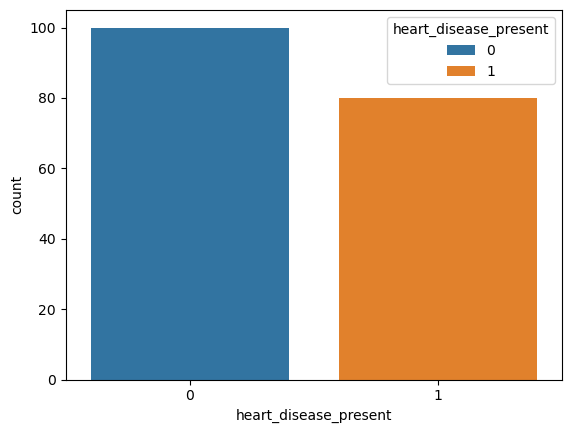

In [22]:
sns.countplot(data=df,x='heart_disease_present',hue='heart_disease_present')
print(df.heart_disease_present.value_counts())

In [23]:
print("No Heart Disease percentage:", (100/180)*100)
print("Heart Disease percentage:", (80/180)*100)

No Heart Disease percentage: 55.55555555555556
Heart Disease percentage: 44.44444444444444


## Analysing the featur's

#### slope_of_peak_exercise_st_segment

In [24]:
df.slope_of_peak_exercise_st_segment.unique()

array([1, 2, 3])

__the slope_of_peak_exercise_st_segment feature has values from 1 to 3__

<Axes: xlabel='slope_of_peak_exercise_st_segment', ylabel='heart_disease_present'>

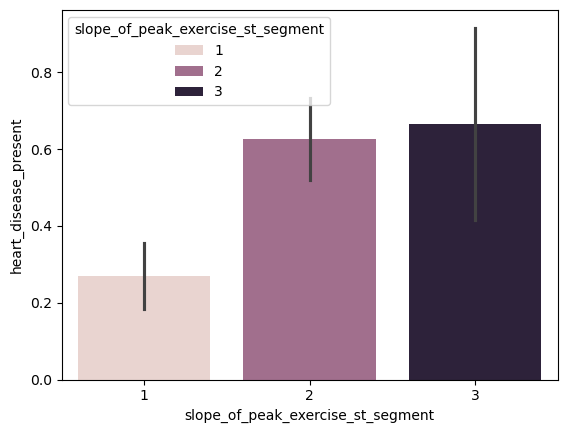

In [25]:
sns.barplot(data=df,x='slope_of_peak_exercise_st_segment',y='heart_disease_present',hue='slope_of_peak_exercise_st_segment')

- The graph shows that patients with slope values 2 and 3 have a higher likelihood of heart disease compared to patients with slope value 1.

#### thal

In [26]:
df.thal.unique()

array(['normal', 'reversible_defect', 'fixed_defect'], dtype=object)

- Contains three categories: normal, reversible defect, and fixed defect.

thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64


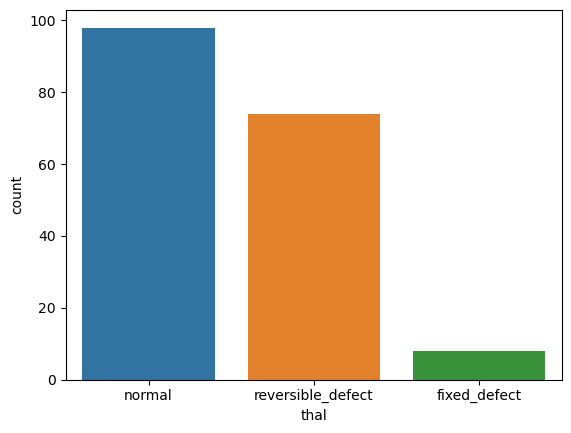

In [27]:
sns.countplot(data=df,x='thal',hue='thal')
print(df.thal.value_counts())

In [28]:
print("normal thal percentage:",(98/180)*100)
print("reversible_defect thal:",(74/180)*100)
print("fixed thal percentage:",(8/180)*100)

normal thal percentage: 54.44444444444444
reversible_defect thal: 41.11111111111111
fixed thal percentage: 4.444444444444445


<Axes: xlabel='thal', ylabel='heart_disease_present'>

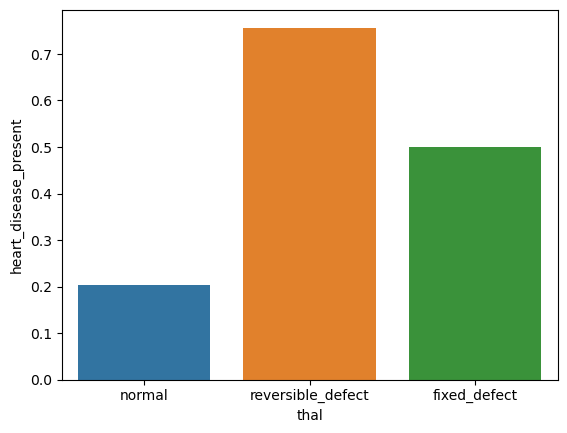

In [29]:
sns.barplot(data=df,x='thal',y='heart_disease_present',hue='thal',ci=None)

- The graph shows that patients with reversible defects have the highest proportion of heart disease, followed by fixed defects, while normal patients have the lowest proportion.

#### resting_blood_pressure

<Axes: xlabel='resting_blood_pressure', ylabel='Count'>

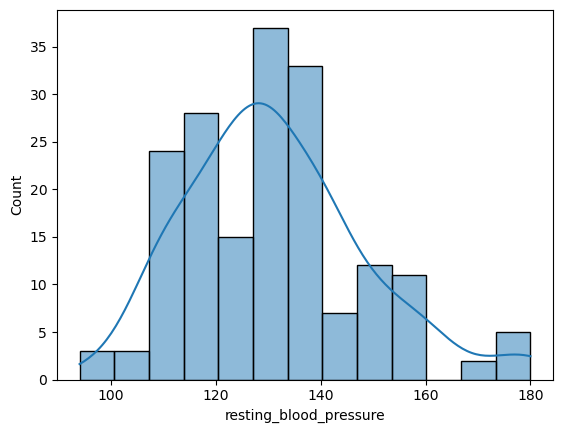

In [30]:
sns.histplot(df.resting_blood_pressure,kde=1)

- The resting blood pressure higher value is 180.
- The Resting blood pressure lower value is 95.
- Most patients have resting blood pressure between 110 and 140.
- The highest frequency is observed around 125–135.

<Axes: xlabel='resting_blood_pressure'>

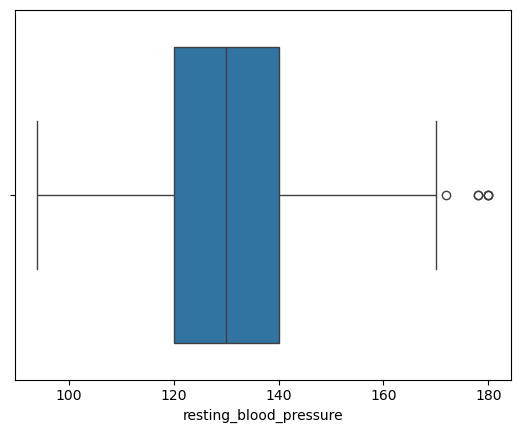

In [31]:
# Check Outlier
sns.boxplot(df.resting_blood_pressure,orient='h')

- The distribution of resting_blood_pressure contains three upper-bound outliers between 172 and 180. 

#### chest_pain_type

In [32]:
df.chest_pain_type.unique()

array([2, 3, 4, 1])

__the chest_pain_type feature has values from 1 to 4__

chest_pain_type
4    82
3    57
2    28
1    13
Name: count, dtype: int64


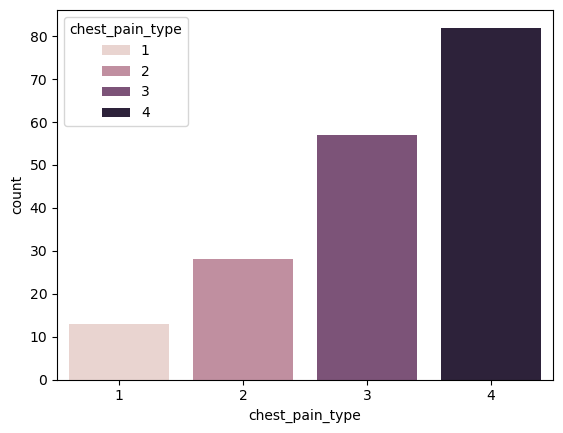

In [33]:
sns.countplot(data=df,x='chest_pain_type',hue='chest_pain_type')
print(df.chest_pain_type.value_counts())

In [34]:
print("chest paint type 1 percentage:",(13/180)*100)
print("chest paint type 2 percentage:",(28/180)*100)
print("chest paint type 3 percentage:",(57/180)*100)
print("chest paint type 4 percentage:",(82/180)*100)

chest paint type 1 percentage: 7.222222222222221
chest paint type 2 percentage: 15.555555555555555
chest paint type 3 percentage: 31.666666666666664
chest paint type 4 percentage: 45.55555555555556


<Axes: xlabel='chest_pain_type', ylabel='heart_disease_present'>

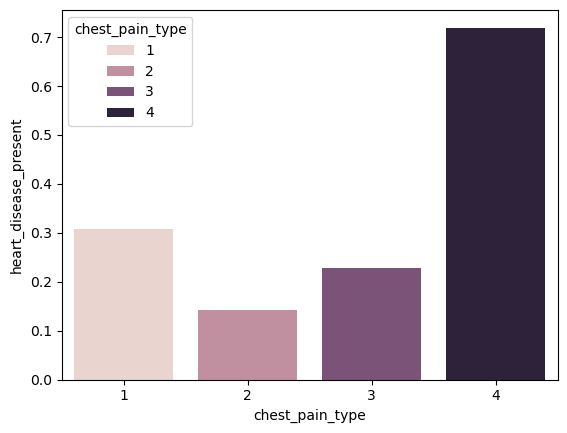

In [35]:
sns.barplot(data=df,x='chest_pain_type',y='heart_disease_present',hue='chest_pain_type',ci=None)

- chest pain type 4 has the highest heart disease issue compared to chest types 1,2 and 3
- chest pain type 2 has the lowest heart disease issue compared to chest types 1,3 and 4

#### num_major_vessels

In [36]:
df.num_major_vessels.unique()

array([0, 3, 2, 1])

__the num_major_vessels featue has values from 0 to 3__

num_major_vessels
0    106
1     37
2     23
3     14
Name: count, dtype: int64


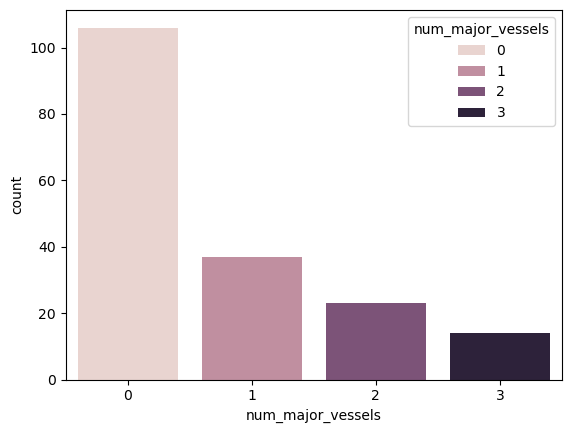

In [37]:
sns.countplot(data=df,x='num_major_vessels',hue='num_major_vessels') 
print(df.num_major_vessels.value_counts())

In [38]:
print("num_major_vessels 0 percentage:",(106/180)*100)
print("num_major_vessels 1 percentage:",(37/180)*100)
print("num_major_vessels 2 percentage:",(23/180)*100)
print("num_major_vessels 3 percentage:",(14/180)*100)

num_major_vessels 0 percentage: 58.88888888888889
num_major_vessels 1 percentage: 20.555555555555554
num_major_vessels 2 percentage: 12.777777777777777
num_major_vessels 3 percentage: 7.777777777777778


<Axes: xlabel='num_major_vessels', ylabel='heart_disease_present'>

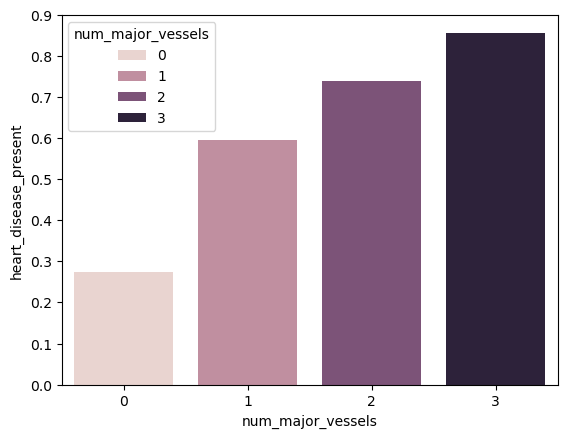

In [39]:
sns.barplot(data=df,x='num_major_vessels',y='heart_disease_present',ci=None,hue='num_major_vessels')

- The graph shows that a lower number of major vessels corresponds to a lower presence of heart disease.
- Patients with 0 major vessels have the lowest rate of heart disease, while those with 3 major vessels have the highest rate.

#### fasting_blood_sugar_gt_120_mg_per_dl

- fasting blood sugar > 120 mg/dl
- in binary 0 and 1
- 0 = Fasting blood sugar ≤ 120 mg/dL
- 1 = Fasting blood sugar > 120 mg/dL

In [40]:
df.fasting_blood_sugar_gt_120_mg_per_dl.unique()

array([0, 1])

fasting_blood_sugar_gt_120_mg_per_dl
0    151
1     29
Name: count, dtype: int64


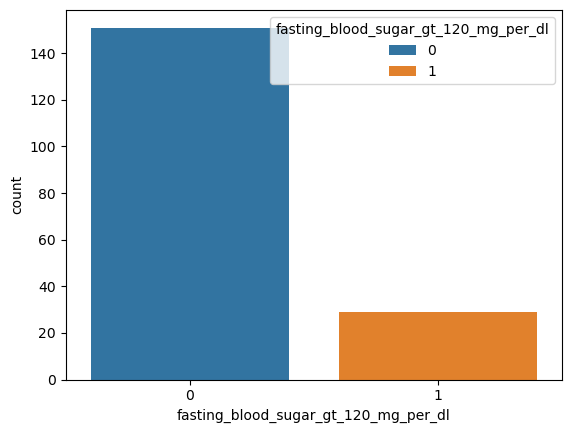

In [41]:
sns.countplot(data=df,x='fasting_blood_sugar_gt_120_mg_per_dl',hue='fasting_blood_sugar_gt_120_mg_per_dl')
print(df.fasting_blood_sugar_gt_120_mg_per_dl.value_counts())

In [42]:
print ("Fasting blood sugar ≤ 120 mg/dL(0):",(151/180)*100)
print("Fasting blood sugar > 120 mg/dL(1):",(29/180)*100)

Fasting blood sugar ≤ 120 mg/dL(0): 83.88888888888889
Fasting blood sugar > 120 mg/dL(1): 16.11111111111111


<Axes: xlabel='fasting_blood_sugar_gt_120_mg_per_dl', ylabel='heart_disease_present'>

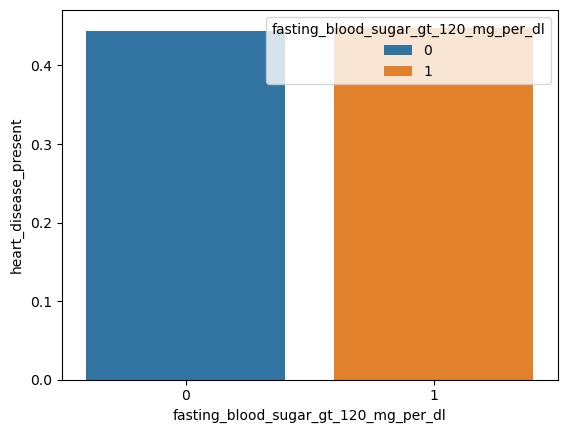

In [43]:
sns.barplot(data=df,x='fasting_blood_sugar_gt_120_mg_per_dl',y='heart_disease_present',hue='fasting_blood_sugar_gt_120_mg_per_dl',ci=None)

__- Fasting blood sugar alone does not show a strong relationship with heart disease in this dataset.__

### resting_ekg_results

In [44]:
df.resting_ekg_results.unique()

array([2, 0, 1])

- resting electrocardiographic results (values 0,1,2)

resting_ekg_results
2    94
0    85
1     1
Name: count, dtype: int64


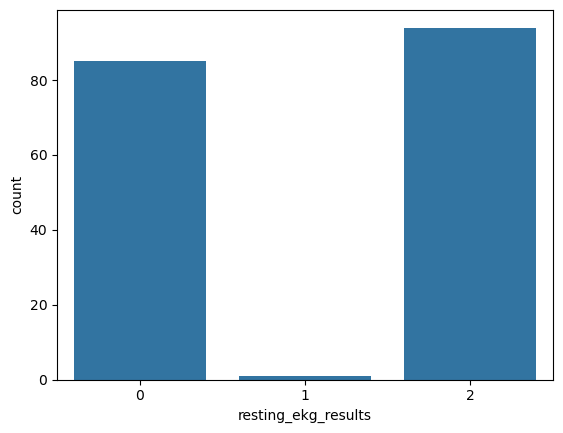

In [45]:
sns.countplot(data=df,x='resting_ekg_results')
print(df.resting_ekg_results.value_counts())

In [46]:
print("resting_ekg_results category 0 percentage of data:",(85/180)*100)
print("resting_ekg_results category 1 percentage of data:",(1/180)*100)
print("resting_ekg_results category 2 percentage of data:",(94/180)*100)

resting_ekg_results category 0 percentage of data: 47.22222222222222
resting_ekg_results category 1 percentage of data: 0.5555555555555556
resting_ekg_results category 2 percentage of data: 52.22222222222223


<Axes: xlabel='resting_ekg_results', ylabel='heart_disease_present'>

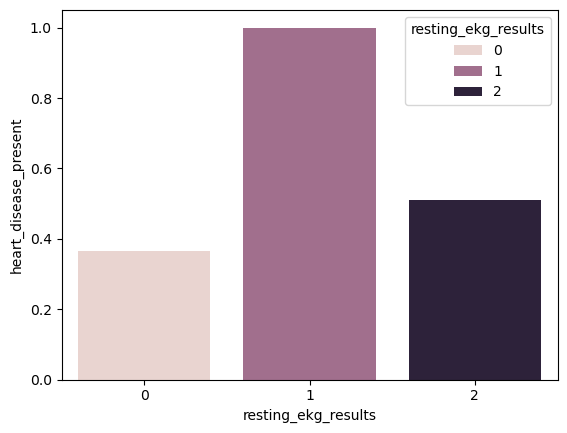

In [47]:
sns.barplot(data=df,x='resting_ekg_results',y='heart_disease_present',hue='resting_ekg_results',ci=None)

- The graph shows that resting ekg result category 1 has the highest heart disease and category 0 has the lowest heart disease

- Resting ECG shows a variation in heart disease occurrence across different categories, suggesting a possible relationship with the target variable.

### serum_cholesterol_mg_per_dl
__serum cholestoral in mg/dl__

<Axes: xlabel='serum_cholesterol_mg_per_dl', ylabel='Count'>

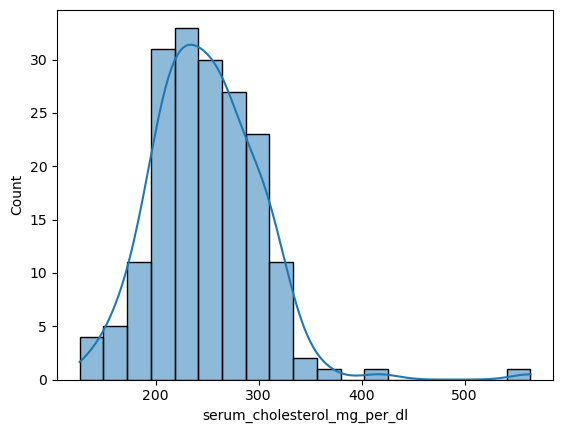

In [48]:
sns.histplot(df.serum_cholesterol_mg_per_dl,kde=1)

 - the Serum choestrol mg per dl higer value is 564.
 - the Serum choestrol mg per dl lower value is 126.
 - most patients have serum cholestrol mg per dl between 180 and 320.
 - The Higest Frequency is observed around 200-320.

<Axes: xlabel='serum_cholesterol_mg_per_dl'>

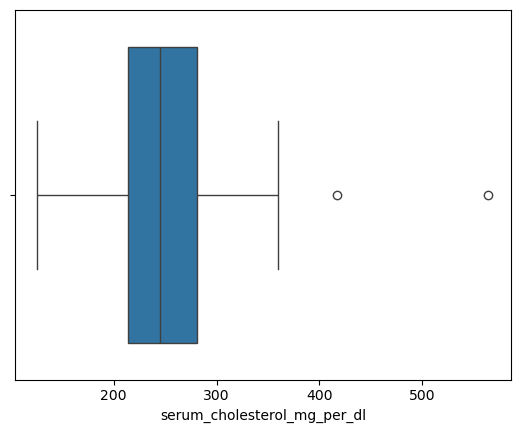

In [49]:
sns.boxplot(df.serum_cholesterol_mg_per_dl,orient='h')

- The distribution of Serum cholestrol mg per dl contains two upper-bound outliers between 400 and 620. 

### oldpeak_eq_st_depression

- ST depression induced by exercise relative to rest, a measure of abnormality in electrocardiograms.

In [50]:
df.oldpeak_eq_st_depression.unique()

array([0. , 1.6, 4.2, 2.6, 0.6, 3.4, 0.4, 0.2, 3.8, 0.9, 1.4, 0.1, 0.3,
       2.3, 1.5, 3. , 2. , 1. , 3.1, 2.5, 0.8, 2.4, 1.8, 1.9, 2.8, 1.2,
       0.5, 2.2, 1.3, 1.1, 0.7, 3.2, 5.6, 6.2])

In [51]:
np.min(df['oldpeak_eq_st_depression'])

0.0

In [52]:
np.max(df['oldpeak_eq_st_depression'])

6.2

<Axes: xlabel='oldpeak_eq_st_depression', ylabel='Count'>

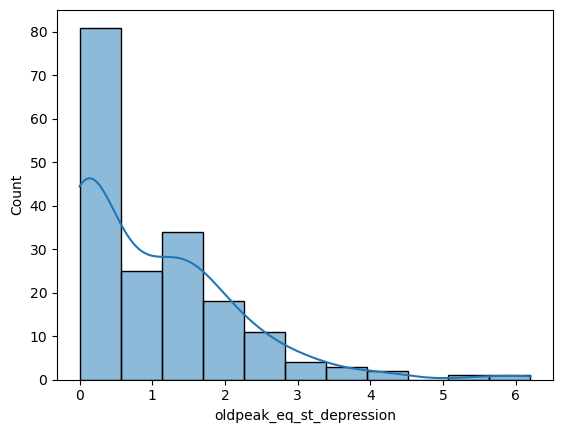

In [53]:
sns.histplot(df.oldpeak_eq_st_depression,kde=1)

 - The graph shows that most values of oldpeak are between 0 and 1.5. The distribution is right-skewed, with only a few higher values.
 - The oldpeak_eq_st_depression lower value is 0.
 - The oldpeak_eq_st_depression higher value is 6.2

<Axes: xlabel='oldpeak_eq_st_depression'>

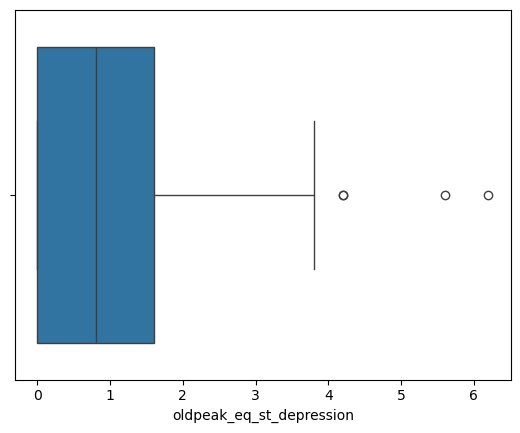

In [54]:
sns.boxplot(df.oldpeak_eq_st_depression,orient='h')

- The distribution of Oldpeak_eq_st_depression contain three upper bound outliers between 4.2 and 6.2

### sex

In [55]:
df.sex.unique()

array([1, 0])

 #### sex:-
  - 1 :- 'male'
  - 0 :- 'female'

sex
1    124
0     56
Name: count, dtype: int64


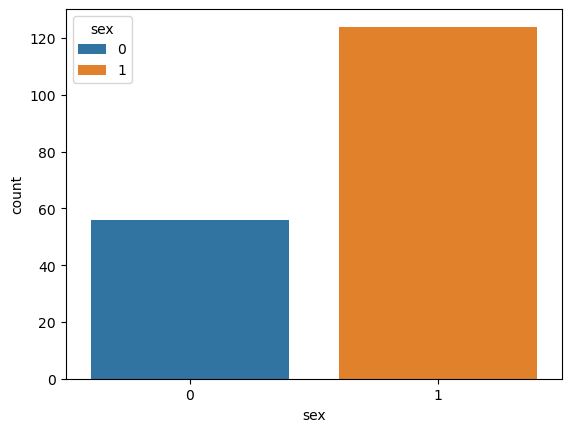

In [56]:
sns.countplot(data=df,x='sex',hue='sex')
print(df.sex.value_counts())

In [57]:
print("male in pecentage:",(124/180)*100)
print("female in percentage:",(56/180)*100)

male in pecentage: 68.88888888888889
female in percentage: 31.11111111111111


<Axes: xlabel='sex', ylabel='count'>

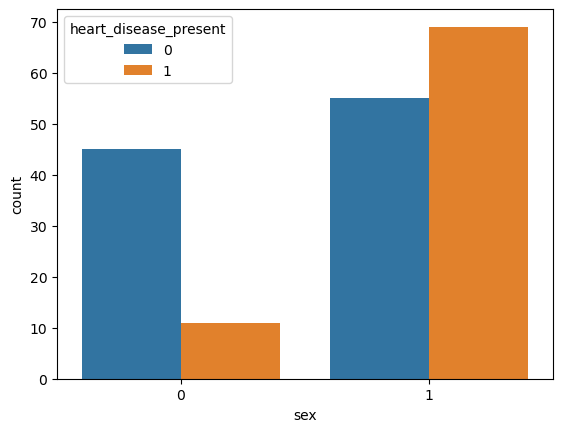

In [58]:
sns.countplot(data=df,x='sex',hue='heart_disease_present')

- The countplot shows that sex category 1(male) has 124 people, while category 0(Female) has 56 people. This indicates that category 1 is more common in the dataset.
- The graph shows that heart disease cases are higher in sex category 1 compared to category 0. This indicates a difference in heart disease distribution across the two sex categories.

### age

In [59]:
df.age.unique()

array([45, 54, 77, 40, 59, 42, 60, 57, 50, 66, 64, 38, 29, 58, 71, 52, 67,
       70, 68, 51, 41, 65, 53, 48, 62, 74, 61, 63, 46, 43, 56, 44, 35, 55,
       49, 47, 37, 69, 39, 34])

In [60]:
print("Minimum age:",np.min(df['age']))
print("Maximum age:",np.max(df['age']))

Minimum age: 29
Maximum age: 77


<Axes: xlabel='age', ylabel='Count'>

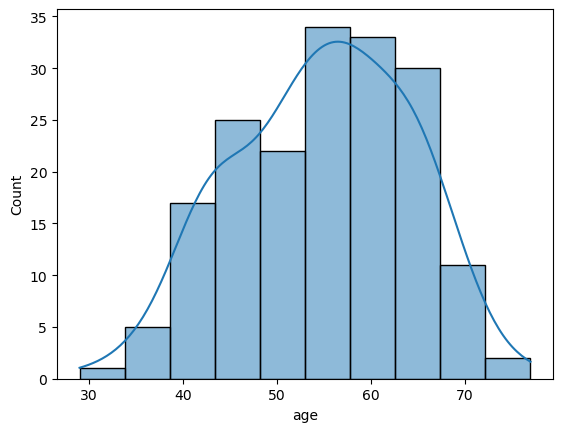

In [61]:
sns.histplot(df.age,kde=1)

- Most patients fall within the 55–65 age group.
- The highest frequency is observed in the 55–60 age group.
- The age range in the dataset is approximately 29–77 years.

<Axes: xlabel='age'>

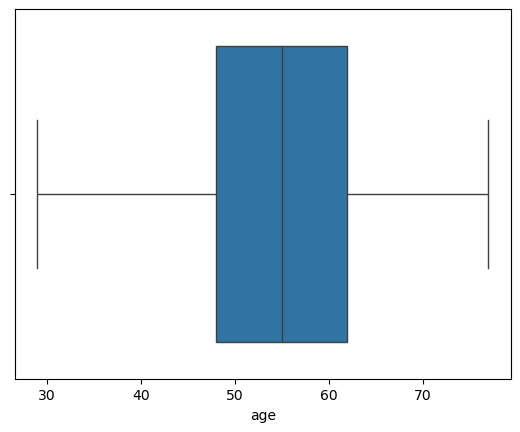

In [62]:
sns.boxplot(df.age,orient='h')

 - The boxplot confirms that the age distribution contains zero outliers

### max_heart_rate_achieved

- this column data show maximum heart rate achieved (beats per minute)

In [63]:
df.max_heart_rate_achieved.unique()

array([170, 158, 162, 181, 145, 150, 157, 112, 140, 151, 178, 152, 182,
       126, 175, 144, 202, 147, 142, 138, 143, 115, 159, 184, 155, 123,
       168, 114, 154, 165, 186, 173, 163, 121, 161, 137, 172, 130, 167,
       141, 166, 125, 103, 120, 132, 169, 179,  99, 177, 160, 156, 109,
       139, 134, 113, 149, 174, 131, 148, 153, 133, 122, 105, 106, 192,
       108,  96, 171, 180, 188, 111,  97, 117])

In [64]:
print("Maximun heart rate:",np.max(df['max_heart_rate_achieved']))
print("Minimum heart rate:",np.min(df['max_heart_rate_achieved']))

Maximun heart rate: 202
Minimum heart rate: 96


<Axes: xlabel='max_heart_rate_achieved', ylabel='Count'>

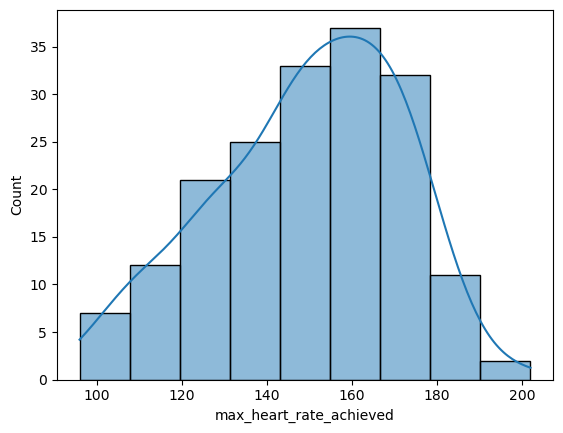

In [65]:
sns.histplot(df.max_heart_rate_achieved,kde=1)

- The highest frequency is observed in 140 to 180
- The max_heart_rate_achived range in dataset approximately 96 to 202.
- most patients have max heart rate between 130 and 178.

<Axes: xlabel='max_heart_rate_achieved'>

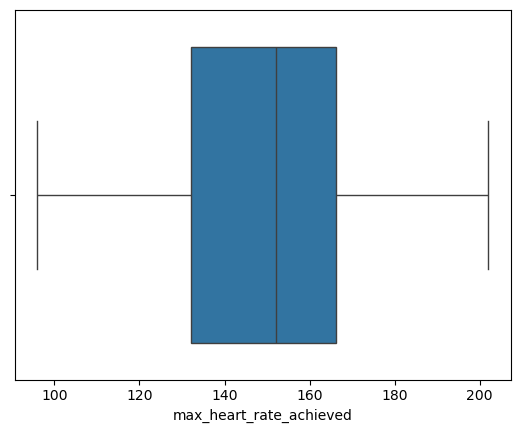

In [66]:
sns.boxplot(df.max_heart_rate_achieved,orient='h')

- the boxplot confirms that the max_heart_rate_achived distribution contain zero outliers.

<Axes: xlabel='age', ylabel='max_heart_rate_achieved'>

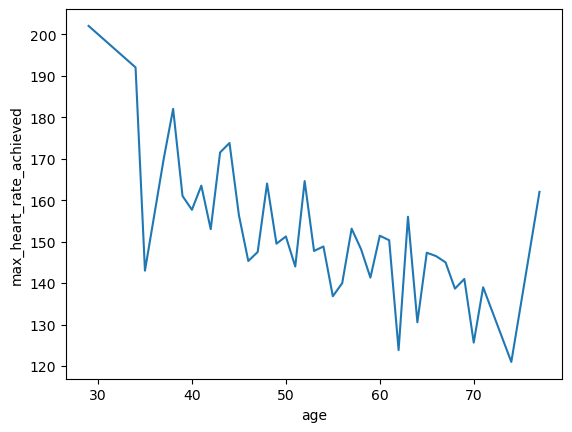

In [67]:
sns.lineplot(data=df,x='age',y='max_heart_rate_achieved',ci=None)

- Younger individuals generally achieve a higher maximum heart rate.
- Maximum heart rate tends to decrease as age increases.
- Older individuals show comparatively lower maximum heart rates.
- Some fluctuations are observed across different age groups.

### exercise_induced_angina

In [68]:
df.exercise_induced_angina.unique()

array([0, 1])

- exercise-induced chest pain
- 0 : False
- 1 : True

exercise_induced_angina
0    123
1     57
Name: count, dtype: int64


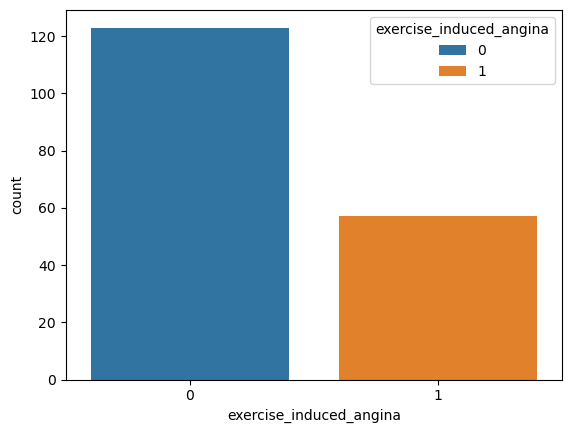

In [69]:
sns.countplot(data=df,x='exercise_induced_angina',hue='exercise_induced_angina')
print(df.exercise_induced_angina.value_counts())

In [70]:
print("percntage of exercise_induced_angina category 0:",(127/180)*100)
print("percntage of exercise_induced_angina category 1:",(57/180)*100)



percntage of exercise_induced_angina category 0: 70.55555555555556
percntage of exercise_induced_angina category 1: 31.666666666666664


<Axes: xlabel='exercise_induced_angina', ylabel='heart_disease_present'>

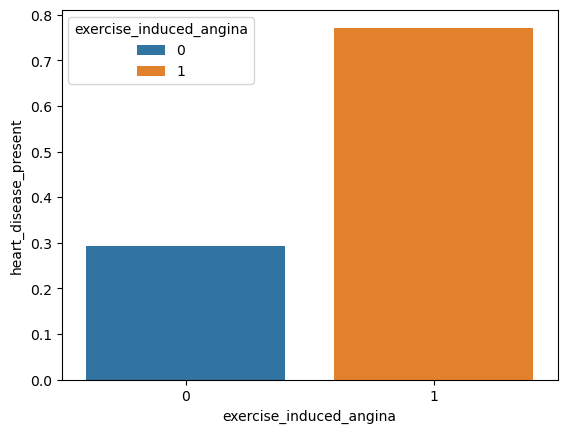

In [71]:
sns.barplot(data=df,x='exercise_induced_angina',y='heart_disease_present',hue='exercise_induced_angina',ci=None)

- Individuals with exercise-induced angina (1) show a higher prevalence of heart disease.
- Individuals without exercise-induced angina (0) show a comparatively lower prevalence.
- This suggests a strong positive relationship between exercise-induced angina and heart disease.

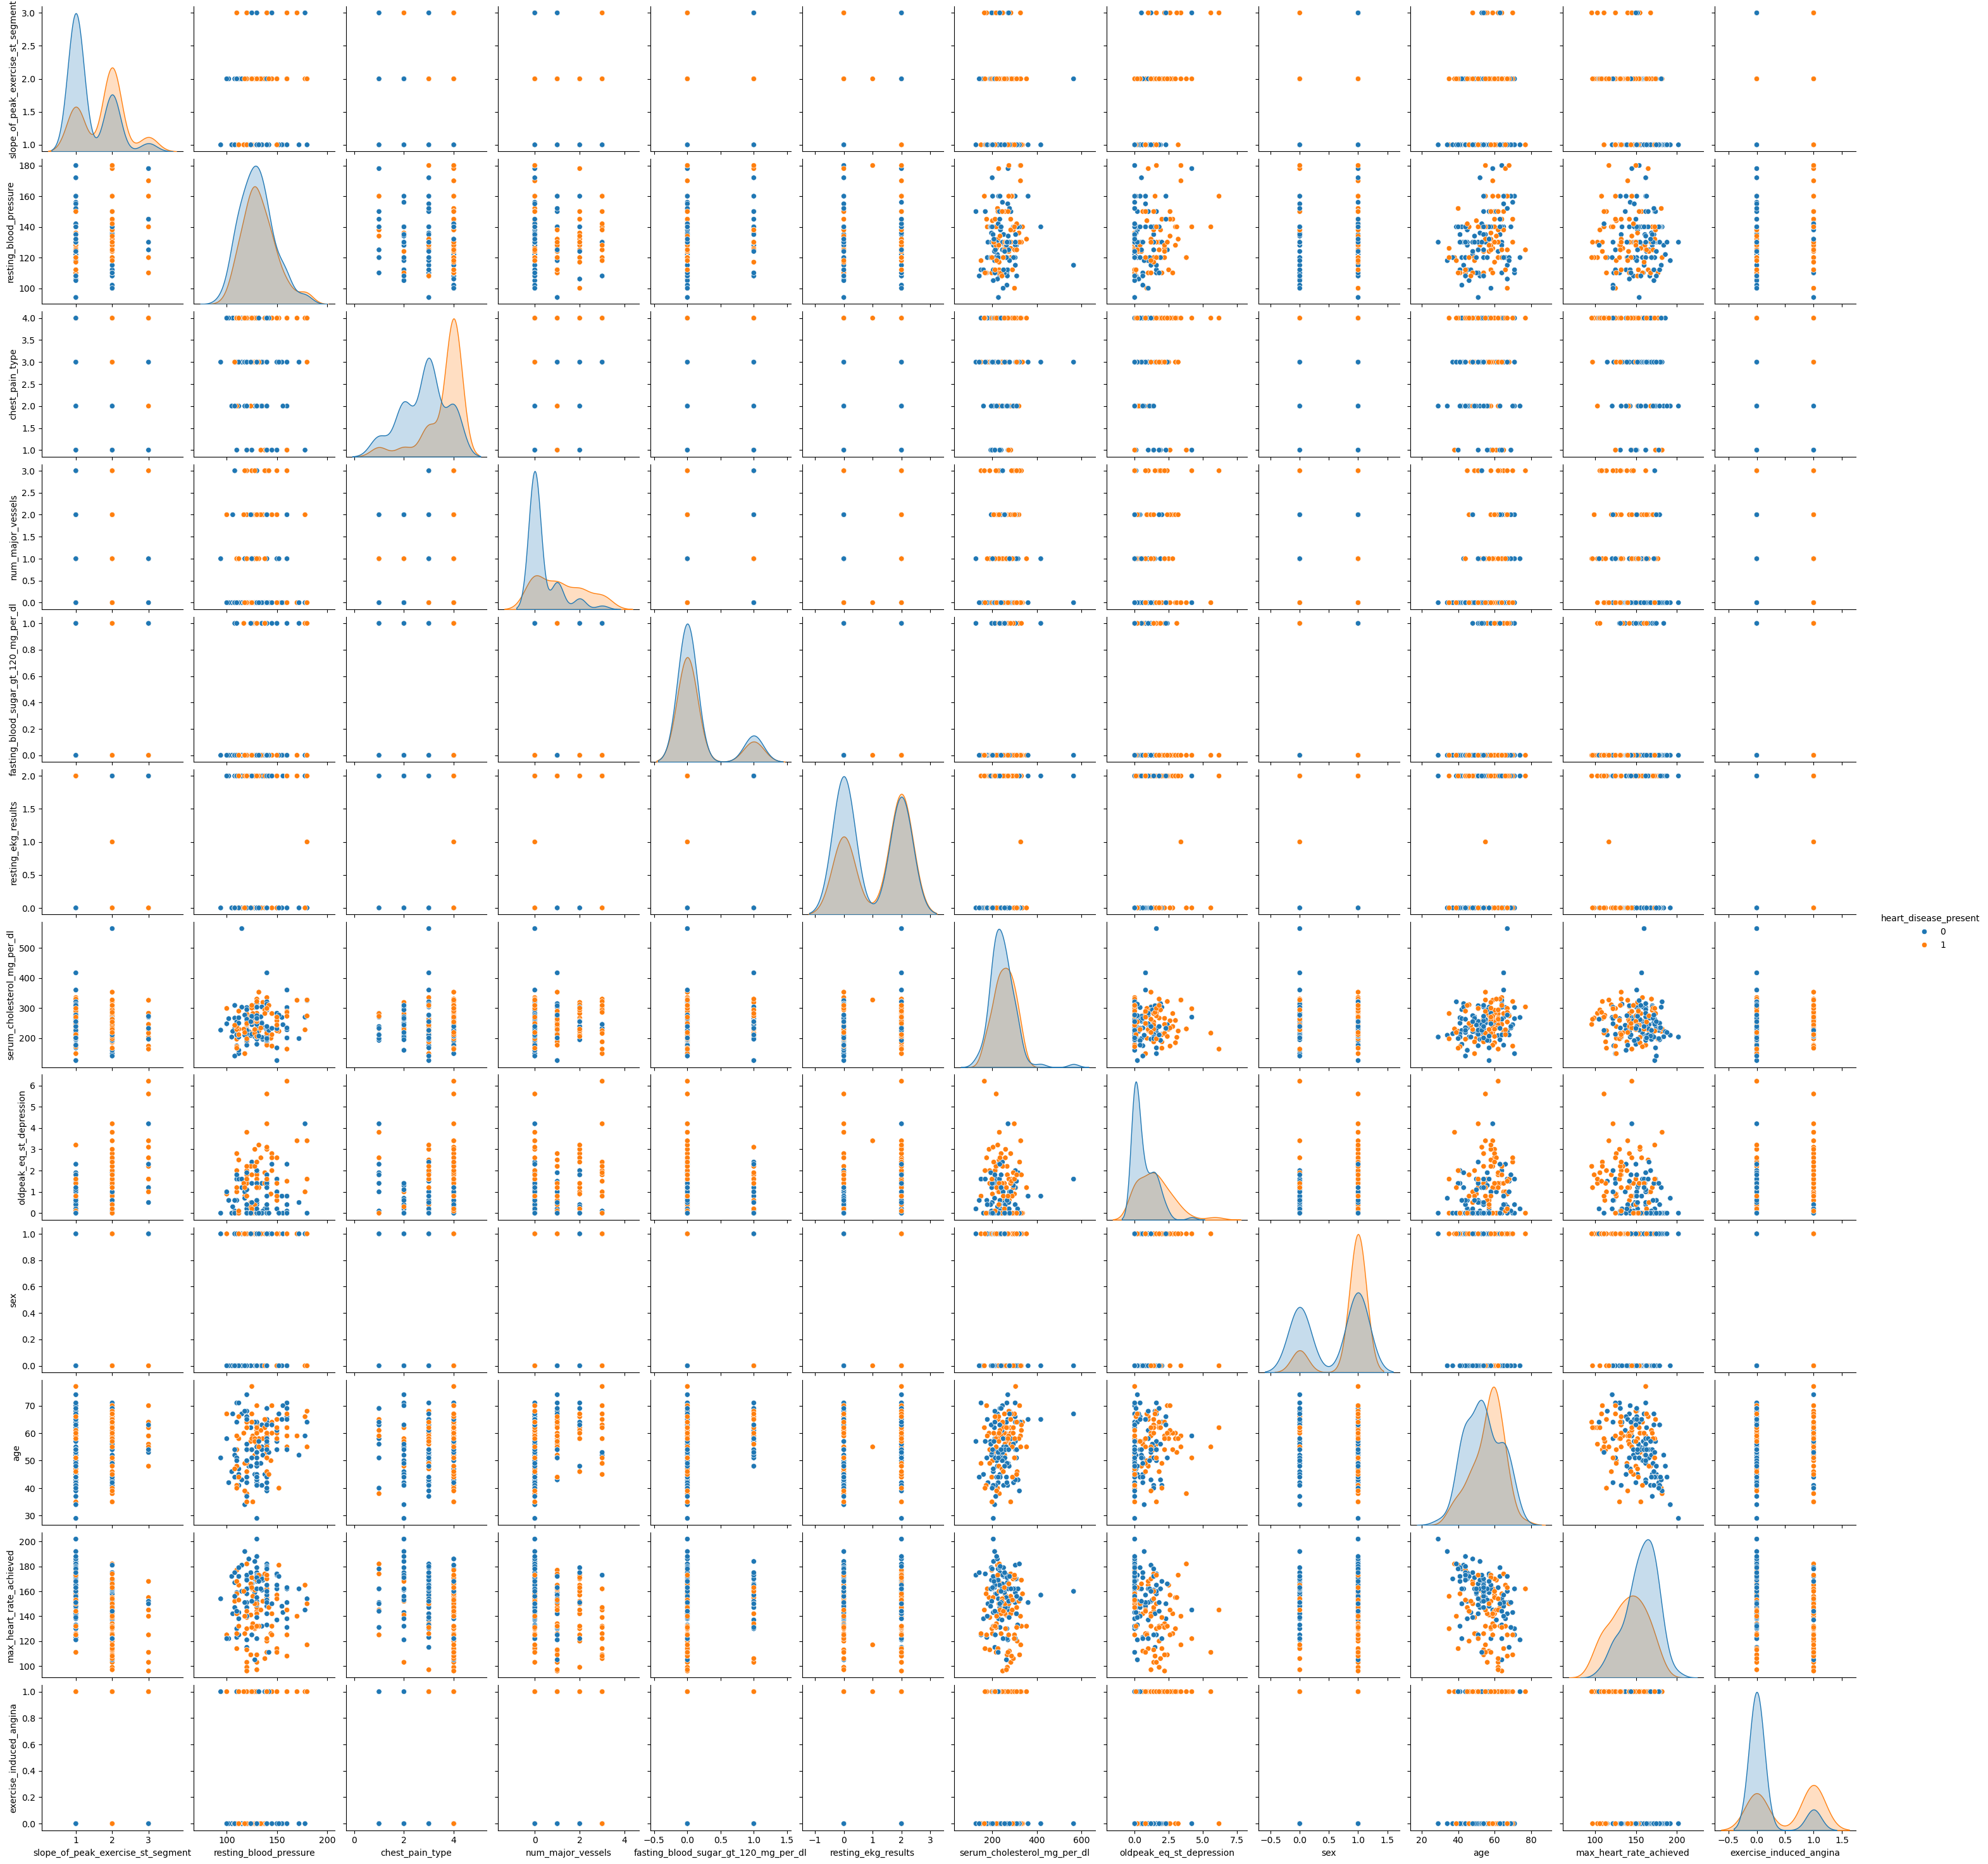

In [72]:
sns.pairplot(data=df,hue='heart_disease_present')

 - The pair plot was used to analyze relationships among multiple features based on heart disease status. Some features show differences between the two target classes, but considerable overlap is observed, suggesting that multiple features may be needed for prediction.

In [73]:
df.corr(numeric_only=True)

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
slope_of_peak_exercise_st_segment,1.000000,0.098287,0.121207,0.076832,0.050199,0.172191,-0.032348,0.615948,0.093340,0.169918,-0.418102,0.225459,0.344224
resting_blood_pressure,0.098287,1.000000,-0.029296,0.042388,0.166570,0.078986,0.144881,0.219026,-0.055589,0.284402,-0.017521,0.123397,0.078506
chest_pain_type,0.121207,-0.029296,1.000000,0.249061,-0.088992,0.033379,0.061213,0.080799,0.086057,0.085001,-0.301792,0.346266,0.412829
num_major_vessels,0.076832,0.042388,0.249061,1.000000,0.169792,0.096656,0.098348,0.214062,0.073107,0.347355,-0.275687,0.153407,0.421519
fasting_blood_sugar_gt_120_mg_per_dl,0.050199,0.166570,-0.088992,0.169792,1.000000,0.053864,0.027560,-0.039055,0.066010,0.176101,0.058369,-0.005956,0.003379
resting_ekg_results,0.172191,0.078986,0.033379,0.096656,0.053864,1.000000,0.170839,0.097321,0.045786,0.126856,-0.102766,0.037773,0.145933
serum_cholesterol_mg_per_dl,-0.032348,0.144881,0.061213,0.098348,0.027560,0.170839,1.000000,-0.021932,-0.152296,0.236211,-0.071038,0.083139,0.079775
oldpeak_eq_st_depression,0.615948,0.219026,0.080799,0.214062,-0.039055,0.097321,-0.021932,1.000000,0.099374,0.189700,-0.341045,0.249167,0.382930
sex,0.093340,-0.055589,0.086057,0.073107,0.066010,0.045786,-0.152296,0.099374,1.000000,-0.148997,-0.053960,0.251096,0.335421
age,0.169918,0.284402,0.085001,0.347355,0.176101,0.126856,0.236211,0.189700,-0.148997,1.000000,-0.394630,0.081811,0.138255


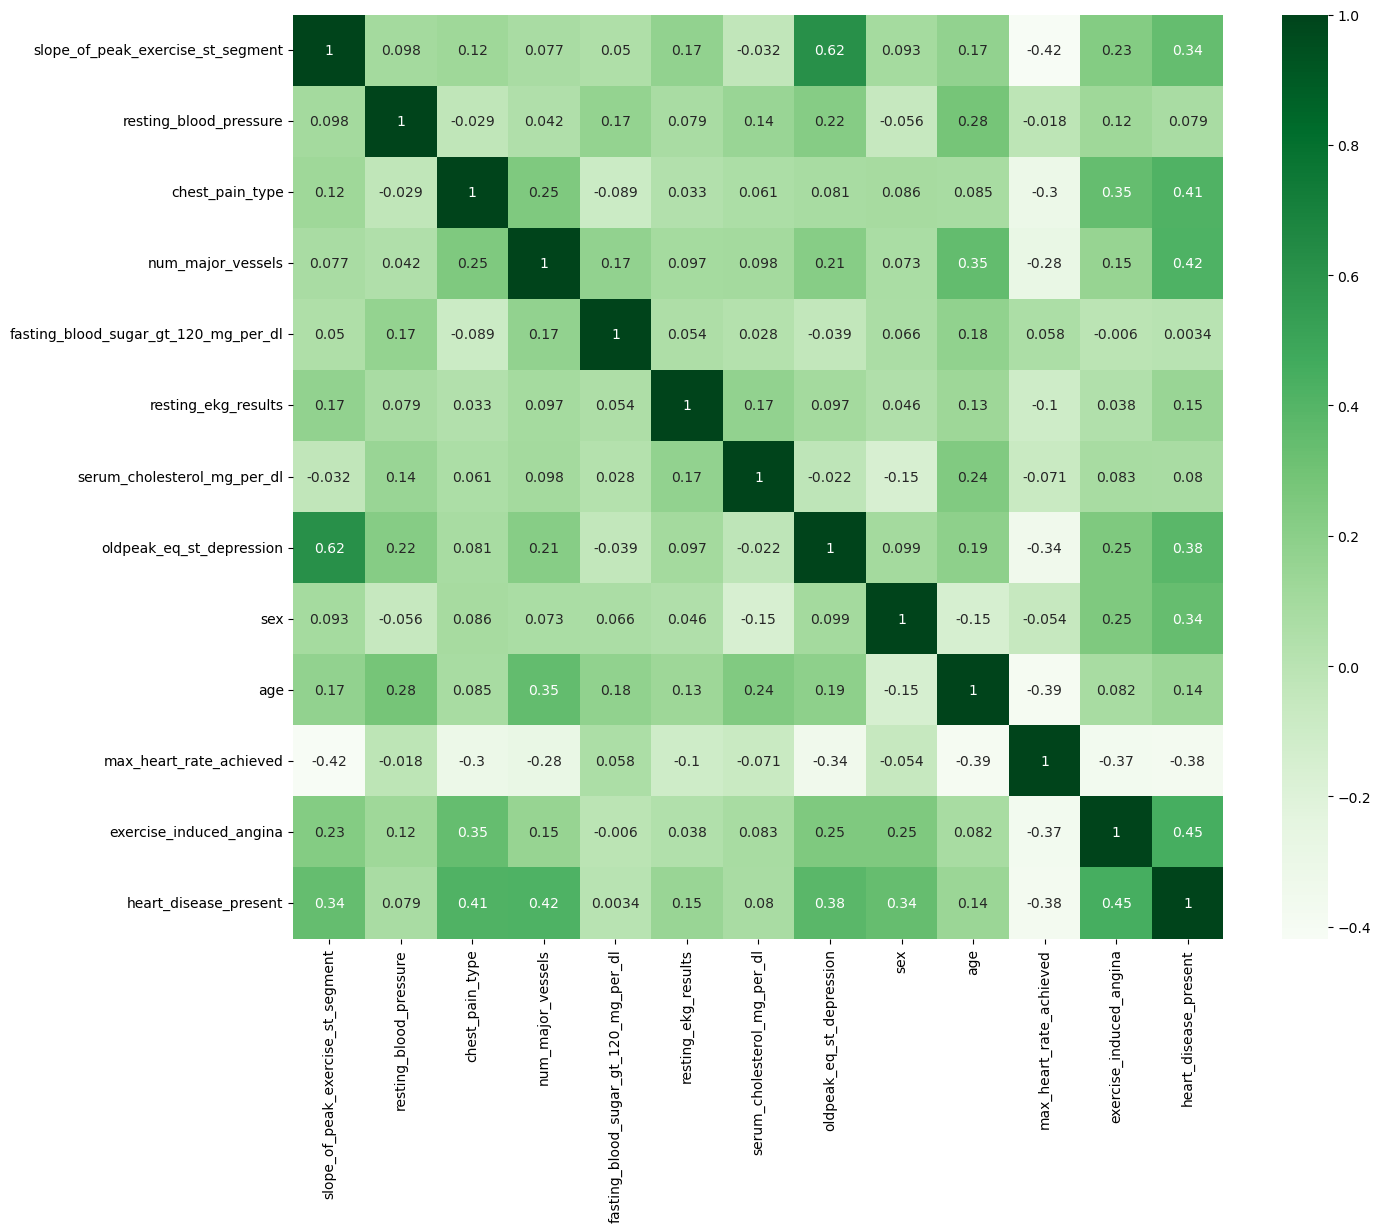

In [74]:
plt.figure(figsize=(15,12))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='Greens')
plt.show()

Multivariate Analysis – Correlation Heatmap
- Exercise-induced angina shows the highest positive correlation (0.45) with heart disease.
- Number of major vessels (0.42) and chest pain type (0.41) also show positive correlations with heart disease.
- Oldpeak (0.38) and slope of peak exercise ST segment (0.34) show positive correlations with the target.
- Maximum heart rate achieved shows a negative correlation (-0.38) with heart disease.
- Fasting blood sugar shows almost no linear correlation (0.0034) with the target.
- Most feature pairs show weak correlations, while slope and oldpeak have a relatively strong correlation (0.62).

## Data Preprocessing

In [75]:
# missing and null value check
print(df.isnull().sum())

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64


In [76]:
df.duplicated().sum()

np.int64(0)

#### Missing Values and Duplicate Records Analysis

- Checked all columns for missing and null values.
- No missing or null values were found.
- Checked the dataset for duplicate records.
- No duplicate records were found.
- The dataset is clean and ready for further analysis.

### Outliers Handeling

- The dataset contains outliers in three columns: resting blood pressure ,serum cholesterol and oldpeak_eq_st_depression.
- The box plot of resting blood pressure shows three upper-bound outliers, ranging from approximately 172 to 180.
- The box plot of serum cholesterol shows two upper-bound outliers, at approximately 420 and 565.
- The box plot of oldpeak_eq_st_depression shows three upper_bound outliers at approximately between 4.2 and 6.2


In [77]:
cols_to_cap = ['resting_blood_pressure', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression']

for col in cols_to_cap:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])

- Preserved all 180 records.
- Avoided unnecessary data loss.
- Limited the impact of extreme values.
- Used the IQR method (Lower Bound and Upper Bound) for capping.

### Not useble column drop

- The patient_id column was dropped because it contains unique identifiers and does not provide meaningful information for model training.

In [78]:
df.drop('patient_id',axis=1,inplace=True)

In [79]:
df.head(5)

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128.0,2,0,0,2,308.0,0.0,1,45,170,0,0
1,2,normal,110.0,3,0,0,0,214.0,1.6,0,54,158,0,0
2,1,normal,125.0,4,3,0,2,304.0,0.0,1,77,162,1,1
3,1,reversible_defect,152.0,4,0,0,0,223.0,0.0,1,40,181,0,1
4,3,reversible_defect,170.0,1,0,0,2,270.0,4.0,1,59,145,0,0


### Encoding and Scaling

 - One-Hot Encoding: Selected thal as a categorical feature for One-Hot Encoding.

 - Scaling: Selected five numerical features (resting_blood_pressure, serum_cholesterol_mg_per_dl, oldpeak_eq_st_depression, age, and max_heart_rate_achieved) for StandardScaler.

- Passthrough: Selected seven features to retain their original values without applying any transformation.

In [80]:
one_hot_encodeing = ['thal']
scaleing = ['resting_blood_pressure','serum_cholesterol_mg_per_dl','oldpeak_eq_st_depression','age','max_heart_rate_achieved']
paas = ['slope_of_peak_exercise_st_segment','chest_pain_type','num_major_vessels','fasting_blood_sugar_gt_120_mg_per_dl','resting_ekg_results','sex','exercise_induced_angina']


In [81]:
def p(x):
    return x   # Defined a custom identity function to return input data without modification.

In [82]:
no_transform = FunctionTransformer(p)  # Used FunctionTransformer to create a no-transformation step.

In [83]:
pipline = ColumnTransformer([("One hot Encoder",OneHotEncoder(),one_hot_encodeing),
                            ("scaleing",StandardScaler(),scaleing),
                            ("Pass Thriugh",no_transform,paas)])

 - Combined all transformations into a single preprocessing pipeline for consistent data preparation.

In [84]:
pipline

,transformers,"[('One hot Encoder', ...), ('scaleing', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,None
,sparse_output,True


In [85]:
pipline.fit_transform(df)

array([[0., 1., 0., ..., 2., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 2., 1., 1.],
       ...,
       [0., 0., 1., ..., 0., 1., 1.],
       [0., 1., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(180, 15))

__Separating Features and Target Variable__

In [86]:
x= df.drop('heart_disease_present',axis=1)
y= df['heart_disease_present']

__Splitting Data into Training and Testing Sets__

In [87]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=22)

__Applying Preprocessing Pipeline__

In [88]:
x_train = pipline.fit_transform(x_train)
x_test = pipline.fit_transform(x_test)

In [89]:
print(x_train.shape)
print(x_test.shape)

print(y_train.shape)
print(y_test.shape)

(144, 15)
(36, 15)
(144,)
(36,)


## Balancing

In [90]:
Counter(y_train)

Counter({0: 80, 1: 64})

 - The target variable contains 144 records, with 80 instances belonging to class 0 and 64 instances belonging to class 1.
 - The distribution is relatively balanced, indicating no significant class imbalance. Therefore, no resampling techniques such as SMOTE or undersampling are required before model training.

## Task 2:-

## Model Fitting

#### Logistic Regression

In [91]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### Note :-
- HT - Hyperparameter Tuning
- Accuracy score print  and show In Percntage
- f1 score and recall Score Noramlly Print

__Training prediction LR__

In [92]:
y_train_pred  = lr.predict(x_train)

In [93]:
accu_score_lr=round(accuracy_score(y_train_pred,y_train)*100,2)
f1_score_lr =f1_score(y_train_pred,y_train)
recall_score_lr =recall_score(y_train_pred,y_train)

print("The accuracy score achieved using Logistic Regression is:",accu_score_lr,"%")
print("The f1 score achived using Logistic Regression is:",f1_score_lr)
print("The recall score achived using Logistic Regression:",recall_score_lr)

The accuracy score achieved using Logistic Regression is: 86.11 %
The f1 score achived using Logistic Regression is: 0.8412698412698413
The recall score achived using Logistic Regression: 0.8548387096774194


 __Testing Prediction LR__

In [94]:
y_pred_lr = lr.predict(x_test)

In [95]:
accu_score_lr1=round(accuracy_score(y_pred_lr,y_test)*100,2)
f1_score_lr1=f1_score(y_pred_lr,y_test)
recall_score_lr1 =recall_score(y_pred_lr,y_test)

print("The accuracy score achieved using Logistic Regression is:",accu_score_lr1,"%")
print("The f1 score achived using Logistic Regression is:",f1_score_lr1)
print("The recall score achived using Logistic Regression:",recall_score_lr1)

The accuracy score achieved using Logistic Regression is: 80.56 %
The f1 score achived using Logistic Regression is: 0.7741935483870968
The recall score achived using Logistic Regression: 0.8


#### SVM

In [96]:
from sklearn.svm import SVC
svm = SVC()
svm.fit(x_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


__Training prediction SVM__

In [97]:
y_tr_svm_pred = svm.predict(x_train)

In [98]:
accu_score_svm = round(accuracy_score(y_tr_svm_pred,y_train)*100,2)
f1_score_svm =f1_score(y_tr_svm_pred,y_train)
recall_score_svm =recall_score(y_tr_svm_pred,y_train)

print("The accuracy score achieved using SVM is:",accu_score_svm,"%")
print("The f1 score achived using  SVM is:",f1_score_svm)
print("The recall score achived using SVM is:",recall_score_svm)

The accuracy score achieved using SVM is: 88.19 %
The f1 score achived using  SVM is: 0.8661417322834646
The recall score achived using SVM is: 0.873015873015873


 __Testing Prediction SVM__

In [99]:
y_test_svm_pred = svm.predict(x_test)

In [100]:
accu_score_svm1 = round(accuracy_score(y_test_svm_pred,y_test)*100,2)
f1_score_svm1=f1_score(y_test_svm_pred,y_test)
recall_score_svm1 = recall_score(y_test_svm_pred,y_test)

print("The accuracy score achieved using SVM is:",accu_score_svm1,"%")
print("The f1 score achived using SVM is:",f1_score_svm1)
print("The recall score achived using SVM is:",recall_score_svm1)

The accuracy score achieved using SVM is: 88.89 %
The f1 score achived using SVM is: 0.8666666666666667
The recall score achived using SVM is: 0.9285714285714286


### SVM using Hyperparameter tuning

In [101]:
para_svm = {'C':[0.01,0.1,1.0,10,100,1000],
           'kernel':['rbf','linear'],
           'gamma':['scale','auto']}

In [102]:
svm_ht = RandomizedSearchCV(estimator=SVC(),cv=3,param_distributions=para_svm,n_iter=50,refit=True,scoring='accuracy',verbose=3)

In [103]:
svm_ht.fit(x_train,y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
[CV 1/3] END ...C=0.01, gamma=scale, kernel=rbf;, score=0.562 total time=   0.0s
[CV 2/3] END ...C=0.01, gamma=scale, kernel=rbf;, score=0.562 total time=   0.0s
[CV 3/3] END ...C=0.01, gamma=scale, kernel=rbf;, score=0.542 total time=   0.0s
[CV 1/3] END C=0.01, gamma=scale, kernel=linear;, score=0.812 total time=   0.0s
[CV 2/3] END C=0.01, gamma=scale, kernel=linear;, score=0.833 total time=   0.0s
[CV 3/3] END C=0.01, gamma=scale, kernel=linear;, score=0.792 total time=   0.0s
[CV 1/3] END ....C=0.01, gamma=auto, kernel=rbf;, score=0.562 total time=   0.0s
[CV 2/3] END ....C=0.01, gamma=auto, kernel=rbf;, score=0.562 total time=   0.0s
[CV 3/3] END ....C=0.01, gamma=auto, kernel=rbf;, score=0.542 total time=   0.0s
[CV 1/3] END .C=0.01, gamma=auto, kernel=linear;, score=0.812 total time=   0.0s
[CV 2/3] END .C=0.01, gamma=auto, kernel=linear;, score=0.833 total time=   0.0s
[CV 3/3] END .C=0.01, gamma=auto, kernel=linear;

,estimator,SVC()
,param_distributions,"{'C': [0.01, 0.1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['rbf', 'linear']}"
,n_iter,50
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


__Training prediction SVM using Hyperparameter Tuning__

In [104]:
y_tr_svm_ht_pred = svm_ht.predict(x_train)

In [105]:
accu_score_svm_ht = round(accuracy_score(y_tr_svm_ht_pred,y_train)*100,2)
f1_score_svm_ht = f1_score(y_tr_svm_ht_pred,y_train)
recall_score_svm_ht =recall_score(y_tr_svm_ht_pred,y_train)

print("The accuracy score achieved using SVM_HT is:",accu_score_svm_ht,"%")
print("The f1 score achived using SVM_HT is:",f1_score_svm_ht)
print("The recall score achived using avm_ht:",recall_score_svm_ht)

The accuracy score achieved using SVM_HT is: 86.81 %
The f1 score achived using SVM_HT is: 0.848
The recall score achived using avm_ht: 0.8688524590163934


__Testing prediction SVM using Hyperparameter Tuning__

In [106]:
y_test_svm_ht_pred = svm_ht.predict(x_test)

In [107]:
accu_score_svm_ht1 = round(accuracy_score(y_test_svm_ht_pred,y_test)*100,2)
f1_score_svm_ht1 = f1_score(y_test_svm_ht_pred,y_test)
recall_score_svm_ht1 =recall_score(y_test_svm_ht_pred,y_test)

print("The accuracy score achieved using SVM_HT is:",accu_score_svm_ht1,"%")
print("The f1 score achived using SVM_HT is:",f1_score_svm_ht1)
print("The recall score achived using avm_ht:",recall_score_svm_ht1)

The accuracy score achieved using SVM_HT is: 83.33 %
The f1 score achived using SVM_HT is: 0.8
The recall score achived using avm_ht: 0.8571428571428571


### Decision Tree

In [108]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


__Traning Prediction DT__

In [109]:
y_tr_dt_pred = dt.predict(x_train)

In [110]:
accu_score_dt = round(accuracy_score(y_tr_dt_pred,y_train)*100,2)
f1_score_dt = f1_score(y_tr_dt_pred,y_train)
recall_score_dt = recall_score(y_tr_dt_pred,y_train)

print("The Accuracy score achived using Decision Tree is:",accu_score_dt,"%")
print("The F1 score achvied using Decision Tree is:",f1_score_dt)
print("The recall score achived using Decision Tree is:",recall_score_dt)

The Accuracy score achived using Decision Tree is: 100.0 %
The F1 score achvied using Decision Tree is: 1.0
The recall score achived using Decision Tree is: 1.0


__Testing Prediction DT__

In [111]:
y_pred_dt =dt.predict(x_test)

In [112]:
accu_score_dt1 = round(accuracy_score(y_test,y_pred_dt)*100,2)
f1_score_dt1 = f1_score(y_test,y_pred_dt)
recall_score_dt1 = recall_score(y_test,y_pred_dt)

print("The Accuracy score achived using Decision Tree is:",accu_score_dt1,"%")
print("The F1 score achvied using Decision Tree is:",f1_score_dt1)
print("The recall score achived using Decision Tree is:",recall_score_dt1)

The Accuracy score achived using Decision Tree is: 77.78 %
The F1 score achvied using Decision Tree is: 0.7647058823529411
The recall score achived using Decision Tree is: 0.8125


- The Decision Tree achieved 100% training accuracy because it learned the training data very closely, including its patterns and possible noise, indicating overfitting.

__Decision tree using Hyperparameter Tunig__

In [113]:
para_dt = {'criterion':['entropy','gini'],
          'splitter':['best','random'],
          'min_samples_split':[2,3,4,5],
          'min_samples_leaf':[2,3,4,5],
          'max_depth':[None,2,3,4,5]}

In [114]:
dt1 = GridSearchCV(estimator=DecisionTreeClassifier(),param_grid=para_dt,scoring='accuracy',verbose=3,refit=True,cv=3)

__Traning Prediction DT (hyper tunig)__

In [115]:
dt1.fit(x_train,y_train)

Fitting 3 folds for each of 320 candidates, totalling 960 fits
[CV 1/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=best;, score=0.771 total time=   0.0s
[CV 2/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=best;, score=0.729 total time=   0.0s
[CV 3/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=best;, score=0.562 total time=   0.0s
[CV 1/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=random;, score=0.792 total time=   0.0s
[CV 2/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=random;, score=0.667 total time=   0.0s
[CV 3/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=2, splitter=random;, score=0.708 total time=   0.0s
[CV 1/3] END criterion=entropy, max_depth=None, min_samples_leaf=2, min_samples_split=3, splitter=best;, score=0.77

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['entropy', 'gini'], 'max_depth': [None, 2, ...], 'min_samples_leaf': [2, 3, ...], 'min_samples_split': [2, 3, ...], ...}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [116]:
y_tr_dt_ht = dt1.predict(x_train)

In [117]:
accu_score_dt_ht = round(accuracy_score(y_tr_dt_ht,y_train)*100,2)
f1_score_dt_ht = f1_score(y_tr_dt_ht,y_train)
recall_score_dt_ht = recall_score(y_tr_dt_ht,y_train)

print("The Accuracy score achived using Decision Tree HT is:",accu_score_dt_ht,"%")
print("The F1 score achvied using Decision Tree HT is:",f1_score_dt_ht)
print("The recall score achived using Decision Tree HT is:",recall_score_dt_ht)

The Accuracy score achived using Decision Tree HT is: 85.42 %
The F1 score achvied using Decision Tree HT is: 0.8205128205128205
The recall score achived using Decision Tree HT is: 0.9056603773584906


__testing Prediction DT (hyper tunig)__

In [118]:
y_pred_dt_ht = dt1.predict(x_test)

In [119]:
accu_score_dt_ht1 = round(accuracy_score(y_pred_dt_ht,y_test)*100,2)
f1_score_dt_ht1 = f1_score(y_pred_dt_ht,y_test)
recall_score_dt_ht1 = recall_score(y_pred_dt_ht,y_test)
print("The Accuracy score achived using Decision Tree HT is:",accu_score_dt_ht1,"%")
print("The F1 score achvied using Decision Tree HT is:",f1_score_dt_ht1)
print("The recall score achived using Decision Tree HT is:",recall_score_dt_ht1)

The Accuracy score achived using Decision Tree HT is: 77.78 %
The F1 score achvied using Decision Tree HT is: 0.7142857142857143
The recall score achived using Decision Tree HT is: 0.8333333333333334


### BaggingClassifier

In [120]:
from sklearn.ensemble import BaggingClassifier

In [121]:
bag= BaggingClassifier()
bag.fit(x_train,y_train)

,estimator,None
,n_estimators,10
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,None
,verbose,0


__Traning Prediction Bagging__

In [122]:
y_tr_bag_pred = bag.predict(x_train)

In [123]:
accu_score_bag = round(accuracy_score(y_tr_bag_pred,y_train)*100,2)
f1_score_bag = f1_score(y_tr_bag_pred,y_train)
recall_score_bag = recall_score(y_tr_bag_pred,y_train)

print("The Accuracy score achived using Bagging Classifier is:",accu_score_bag,"%")
print("The f1 score achived using Bagging Classifier is",f1_score_bag)
print("The recall score achived using Bagging Classifier is:",recall_score_bag)

The Accuracy score achived using Bagging Classifier is: 97.92 %
The f1 score achived using Bagging Classifier is 0.9763779527559056
The recall score achived using Bagging Classifier is: 0.9841269841269841


__Testing Prediction Bagging__

In [124]:
y_pred_bag = bag.predict(x_test)

In [125]:
accu_score_bag1 = round(accuracy_score(y_pred_bag,y_test)*100,2)
f1_score_bag1= f1_score(y_pred_bag,y_test)
recall_score_bag1 = recall_score(y_pred_bag,y_test)

print("The Accuracy score achived using Bagging Classifier is:",accu_score_bag1,"%")
print("The f1 score achived using Bagging Classifier is",f1_score_bag1,"%")
print("The recall score achived using Bagging Classifier is:",recall_score_bag1)

The Accuracy score achived using Bagging Classifier is: 75.0 %
The f1 score achived using Bagging Classifier is 0.7096774193548387 %
The recall score achived using Bagging Classifier is: 0.7333333333333333


### BaggingClassifier using Hyperparameter Tuning

In [126]:
parm_bagging = {
    'n_estimators':[50,100,150],
    'max_samples': [0.7, 0.8, 0.9, 1.0],
    'max_features': [0.7, 0.8, 0.9, 1.0],
    'bootstrap': [True]}

In [127]:
bag_ht  = GridSearchCV(estimator=BaggingClassifier(),cv=3,scoring='accuracy',param_grid=parm_bagging,refit=True,verbose=3)

In [128]:
bag_ht.fit(x_train,y_train)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
[CV 1/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=50;, score=0.812 total time=   0.3s
[CV 2/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=50;, score=0.729 total time=   0.3s
[CV 3/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=50;, score=0.771 total time=   0.3s
[CV 1/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=100;, score=0.792 total time=   0.7s
[CV 2/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=100;, score=0.729 total time=   0.8s
[CV 3/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=100;, score=0.812 total time=   0.8s
[CV 1/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=150;, score=0.812 total time=   1.1s
[CV 2/3] END bootstrap=True, max_features=0.7, max_samples=0.7, n_estimators=150;, score=0.729 total time=   1.0s
[CV 3/3] END bootstrap=True, 

,estimator,BaggingClassifier()
,param_grid,"{'bootstrap': [True], 'max_features': [0.7, 0.8, ...], 'max_samples': [0.7, 0.8, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,estimator,None


__Traning Prediction Bagging (hyper tuning)__

In [129]:
y_tr_bg_ht_pre = bag_ht.predict(x_train)

In [130]:
accu_score_bag_ht = round(accuracy_score(y_tr_bg_ht_pre,y_train)*100,2)
f1_score_bag_ht = f1_score(y_tr_bg_ht_pre,y_train)
recall_score_bag_ht = recall_score(y_tr_bg_ht_pre,y_train)

print("The Accuracy score achived using Bagging Classifier HT is:",accu_score_bag_ht,"%")
print("The f1 score achived using Bagging Classifier HT is:",f1_score_bag_ht)
print("The recall score achived using Bagging Classifier is HT:",recall_score_bag_ht)

The Accuracy score achived using Bagging Classifier HT is: 100.0 %
The f1 score achived using Bagging Classifier HT is: 1.0
The recall score achived using Bagging Classifier is HT: 1.0


__Testing Prediction Bagging (hyper tuning)__

In [131]:
y_pred_bag_ht = bag_ht.predict(x_test)

In [132]:
accu_score_bag_ht1 = round(accuracy_score(y_pred_bag_ht,y_test)*100,2)
f1_score_bag_ht1= f1_score(y_pred_bag_ht,y_test)
recall_score_bag_ht1 = recall_score(y_pred_bag_ht,y_test)

print("The Accuracy score achived using Bagging Classifier  HT is:",accu_score_bag_ht1,"%")
print("The f1 score achived using Bagging Classifier  HT is",f1_score_bag_ht1)
print("The recall score achived using Bagging Classifier is HT:",recall_score_bag_ht1)

The Accuracy score achived using Bagging Classifier  HT is: 83.33 %
The f1 score achived using Bagging Classifier  HT is 0.8125
The recall score achived using Bagging Classifier is HT: 0.8125


#### Random Forest

In [133]:
from sklearn.ensemble import RandomForestClassifier

In [134]:
rf =RandomForestClassifier()
rf.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


__Training Prediction Random Forest__

In [135]:
y_tr_rf_pre = rf.predict(x_train)

In [136]:
accu_score_rf =round(accuracy_score(y_tr_rf_pre,y_train)*100,2)
f1_score_rf = f1_score(y_tr_rf_pre,y_train)
recall_score_rf =recall_score(y_tr_rf_pre,y_train)

print("The Accuracy score achived using Random Forest is:",accu_score_rf,'%')
print("The F1 score achived using Random Forest is:",f1_score_rf)
print("The recall score achived using Random Forest is:",recall_score_rf)

The Accuracy score achived using Random Forest is: 100.0 %
The F1 score achived using Random Forest is: 1.0
The recall score achived using Random Forest is: 1.0


__testing Prediction Random Forest__

In [137]:
y_pred_rf = rf.predict(x_test)

In [138]:
accu_score_rf1 = round(accuracy_score(y_pred_rf,y_test)*100,2)
f1_score_rf1 =f1_score(y_pred_rf,y_test)
recall_score_rf1 =recall_score(y_pred_rf,y_test)

print("The Accuracy score achived using Random Forest is:",accu_score_rf1,'%')
print("The F1 score achived using Random Forest is:",f1_score_rf1)
print("The recall score achived using Random Forest is:",recall_score_rf1)

The Accuracy score achived using Random Forest is: 83.33 %
The F1 score achived using Random Forest is: 0.8125
The recall score achived using Random Forest is: 0.8125


### Random Forest Usng Hyperparameter Tuning

In [139]:
parm_rf ={"criterion":["gini","entropy"],
"min_samples_split":[2,3,4,5],
"min_samples_leaf":[2,3,4,5],
"max_depth":[None,2,3,4,5],
"n_estimators":[100,150,200]}

In [140]:
rf_ht = RandomizedSearchCV(estimator=RandomForestClassifier(),param_distributions=parm_rf,scoring='accuracy',refit=True,cv=3,verbose=3,n_iter=50)

In [141]:
rf_ht.fit(x_train,y_train)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV 1/3] END criterion=entropy, max_depth=2, min_samples_leaf=3, min_samples_split=5, n_estimators=150;, score=0.812 total time=   0.6s
[CV 2/3] END criterion=entropy, max_depth=2, min_samples_leaf=3, min_samples_split=5, n_estimators=150;, score=0.750 total time=   0.6s
[CV 3/3] END criterion=entropy, max_depth=2, min_samples_leaf=3, min_samples_split=5, n_estimators=150;, score=0.833 total time=   0.6s
[CV 1/3] END criterion=gini, max_depth=3, min_samples_leaf=5, min_samples_split=5, n_estimators=200;, score=0.812 total time=   0.9s
[CV 2/3] END criterion=gini, max_depth=3, min_samples_leaf=5, min_samples_split=5, n_estimators=200;, score=0.771 total time=   0.9s
[CV 3/3] END criterion=gini, max_depth=3, min_samples_leaf=5, min_samples_split=5, n_estimators=200;, score=0.792 total time=   0.9s
[CV 1/3] END criterion=entropy, max_depth=4, min_samples_leaf=2, min_samples_split=4, n_estimators=150;, score=0.812 total time=   

,estimator,RandomForestClassifier()
,param_distributions,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 2, ...], 'min_samples_leaf': [2, 3, ...], 'min_samples_split': [2, 3, ...], ...}"
,n_iter,50
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


__Training Prediction Random Forest ( hyper Tuning)__

In [142]:
y_tr_rf_ht_pre = rf_ht.predict(x_train)

In [143]:
accu_score_rf_ht =round(accuracy_score(y_tr_rf_ht_pre,y_train)*100,2)
f1_score_rf_ht= f1_score(y_tr_rf_ht_pre,y_train)
recall_score_rf_ht =recall_score(y_tr_rf_ht_pre,y_train)


print("The Accuracy score achived using Random Forest HT is:",accu_score_rf_ht,'%')
print("The F1 score achived using Random Forest  HT is:",f1_score_rf_ht)
print("The recall score achived using Random Forest  HT is:",recall_score_rf_ht)

The Accuracy score achived using Random Forest HT is: 85.42 %
The F1 score achived using Random Forest  HT is: 0.8292682926829268
The recall score achived using Random Forest  HT is: 0.864406779661017


__Testing Prediction Random Forest (Hyper Tuning)__

In [144]:
y_pred_rf_ht = rf_ht.predict(x_test)

In [145]:
accu_score_rf_ht1 =round(accuracy_score(y_pred_rf_ht,y_test)*100,2)
f1_score_rf_ht1= f1_score(y_pred_rf_ht,y_test)
recall_score_rf_ht1 =recall_score(y_tr_rf_ht_pre,y_train)

print("The Accuracy score achived using Random Forest HT is:",accu_score_rf_ht1,'%')
print("The F1 score achived using Random Forest  HT is:",f1_score_rf_ht1)
print("The recall score achived using Random Forest  HT is:",recall_score_rf_ht1)

The Accuracy score achived using Random Forest HT is: 83.33 %
The F1 score achived using Random Forest  HT is: 0.8125
The recall score achived using Random Forest  HT is: 0.864406779661017


### Gradient boosting

In [146]:
from sklearn.ensemble import GradientBoostingClassifier

In [147]:
gb = GradientBoostingClassifier()
gb.fit(x_train,y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


__Trainning Prediction Gradient boosting__

In [148]:
y_tr_gb_pre = gb.predict(x_train)

In [149]:
accu_score_gb = round(accuracy_score(y_tr_gb_pre,y_train)*100,2)
f1_score_gb = f1_score(y_tr_gb_pre,y_train)
recall_score_gb =recall_score(y_tr_gb_pre,y_train)

print('The Accuracy score achived using Gradient boosting:',accu_score_gb,"%")
print("The F1 score achived using Gradient boosting:",f1_score_gb)
print("The recall score achived using Gradient Boosting:",recall_score_gb)

The Accuracy score achived using Gradient boosting: 100.0 %
The F1 score achived using Gradient boosting: 1.0
The recall score achived using Gradient Boosting: 1.0


__Testing Gradient Bossting__

In [150]:
y_pred_gb = gb.predict(x_test)

In [151]:
accu_score_gb1 = round(accuracy_score(y_pred_gb,y_test)*100,2)
f1_score_gb1 =f1_score(y_pred_gb,y_test)
recall_score_gb1 =recall_score(y_pred_gb,y_test)

print('The Accuracy score achived using Gradient boosting:',accu_score_gb1,"%")
print("The F1 score achived using Gradient boosting:",f1_score_gb1)
print("The recall score achived using Gradient Boosting:",recall_score_gb1)

The Accuracy score achived using Gradient boosting: 80.56 %
The F1 score achived using Gradient boosting: 0.7878787878787878
The recall score achived using Gradient Boosting: 0.7647058823529411


### Gradient Boosting using Hyperparameter Tuning

In [152]:
para_gb = {'learning_rate':[0.01,0.1,1,10],
          'max_depth':[None,2,3],
          'n_estimators':[100,150,200]}

In [153]:
gb_ht = GridSearchCV(estimator=GradientBoostingClassifier(),param_grid=para_gb,cv=3,scoring='accuracy',refit=True,verbose=3)

In [154]:
gb_ht.fit(x_train,y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
[CV 1/3] END learning_rate=0.01, max_depth=None, n_estimators=100;, score=0.771 total time=   0.6s
[CV 2/3] END learning_rate=0.01, max_depth=None, n_estimators=100;, score=0.646 total time=   0.5s
[CV 3/3] END learning_rate=0.01, max_depth=None, n_estimators=100;, score=0.500 total time=   0.5s
[CV 1/3] END learning_rate=0.01, max_depth=None, n_estimators=150;, score=0.729 total time=   1.0s
[CV 2/3] END learning_rate=0.01, max_depth=None, n_estimators=150;, score=0.625 total time=   0.8s
[CV 3/3] END learning_rate=0.01, max_depth=None, n_estimators=150;, score=0.521 total time=   0.8s
[CV 1/3] END learning_rate=0.01, max_depth=None, n_estimators=200;, score=0.771 total time=   1.3s
[CV 2/3] END learning_rate=0.01, max_depth=None, n_estimators=200;, score=0.646 total time=   1.1s
[CV 3/3] END learning_rate=0.01, max_depth=None, n_estimators=200;, score=0.521 total time=   1.2s
[CV 1/3] END learning_rate=0.01, max_depth=2, n

,estimator,GradientBoostingClassifier()
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [None, 2, ...], 'n_estimators': [100, 150, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [155]:
gb_ht.best_params_

{'learning_rate': 1, 'max_depth': 2, 'n_estimators': 100}

__Training Prediction Gradient Boosting (HT)__

In [156]:
y_tr_gb_ht_pre = gb_ht.predict(x_train)

In [157]:
accu_score_gb_ht = round(accuracy_score(y_tr_gb_ht_pre,y_train)*100,2)
f1_score_gb_ht = f1_score(y_tr_gb_ht_pre,y_train)
recall_score_gb_ht =recall_score(y_tr_gb_ht_pre,y_train)

print('The Accuracy score achived using Gradient boosting HT:',accu_score_gb_ht,"%")
print("The F1 score achived using Gradient boosting HT:",f1_score_gb_ht)
print("The recall score achived using Gradient Bosstng:",recall_score_gb_ht)

The Accuracy score achived using Gradient boosting HT: 100.0 %
The F1 score achived using Gradient boosting HT: 1.0
The recall score achived using Gradient Bosstng: 1.0


__Training Prediction Gradient Boosting (HT)__

In [158]:
y_pred_gb_ht = gb_ht.predict(x_test)

In [159]:
accu_score_gb_ht1 = round(accuracy_score(y_pred_gb_ht,y_test)*100,2)
f1_score_gb_ht1 =f1_score(y_pred_gb_ht,y_test)
recall_score_gb_ht1 = recall_score(y_pred_gb_ht,y_test)

print('The Accuracy score achived using Gradient boosting:',accu_score_gb_ht1,"%")
print("The F1 score achived using Gradient boosting:",f1_score_gb_ht1)
print("The recall score achived using Gradient Bosstng:",recall_score_gb_ht1)

The Accuracy score achived using Gradient boosting: 72.22 %
The F1 score achived using Gradient boosting: 0.6428571428571429
The recall score achived using Gradient Bosstng: 0.75


### ANN

In [160]:
from sklearn.neural_network import MLPClassifier

In [161]:
ann = MLPClassifier()
ann.fit(x_train,y_train)

,hidden_layer_sizes,"(100,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,None


In [162]:
y_tr_ann_pred = ann.predict(x_train)

In [163]:
accu_score_ann = round(accuracy_score(y_tr_ann_pred,y_train)*100,2)
f1_score_ann = f1_score(y_tr_ann_pred,y_train)
recall_score_ann = recall_score(y_tr_ann_pred,y_train)

print("the Accuracy score achived using ANN:",accu_score_ann,"%")
print("The f1 score achived using ANN:",f1_score_ann)
print("The recall score achived using ANN:",recall_score_ann)

the Accuracy score achived using ANN: 90.97 %
The f1 score achived using ANN: 0.896
The recall score achived using ANN: 0.9180327868852459


In [164]:
y_pred_ann = ann.predict(x_test)

In [165]:
accu_score_ann1 = round(accuracy_score(y_pred_ann,y_test)*100,2)
f1_score_ann1 = f1_score(y_pred_ann,y_test)
recall_score_ann1 = recall_score(y_pred_ann,y_test)
                                
print("the Accuracy score achived using ANN:",accu_score_ann1,"%")
print("The f1 score achived using ANN:",f1_score_ann1)
print("The recall score achived using ANN:",recall_score_ann1)

the Accuracy score achived using ANN: 83.33 %
The f1 score achived using ANN: 0.7857142857142857
The recall score achived using ANN: 0.9166666666666666


##  Model Comparison Report

### ALL Algorthim Accuracy Score

In [166]:
accu_score = [accu_score_lr1,accu_score_svm1,accu_score_svm_ht1,accu_score_dt1,accu_score_dt_ht1,accu_score_bag1,accu_score_bag_ht1,accu_score_rf1,accu_score_rf_ht1,accu_score_gb1,accu_score_gb_ht1,accu_score_ann1]
algorithm = ['Logistic Regression','SVM','SVM HT','Decision Tree','Decision Tree HT','Bagging Classifier','Bagging Classifier HT','Random Forest','Random Forest HT','Gradient Boosting','Gradient Boosting HT','ANN']

In [167]:
for i in range(len(algorithm)):
    print("The accuracy Score achived usnig "+algorithm[i]+" is: "+str(accu_score[i])+"%")

The accuracy Score achived usnig Logistic Regression is: 80.56%
The accuracy Score achived usnig SVM is: 88.89%
The accuracy Score achived usnig SVM HT is: 83.33%
The accuracy Score achived usnig Decision Tree is: 77.78%
The accuracy Score achived usnig Decision Tree HT is: 77.78%
The accuracy Score achived usnig Bagging Classifier is: 75.0%
The accuracy Score achived usnig Bagging Classifier HT is: 83.33%
The accuracy Score achived usnig Random Forest is: 83.33%
The accuracy Score achived usnig Random Forest HT is: 83.33%
The accuracy Score achived usnig Gradient Boosting is: 80.56%
The accuracy Score achived usnig Gradient Boosting HT is: 72.22%
The accuracy Score achived usnig ANN is: 83.33%


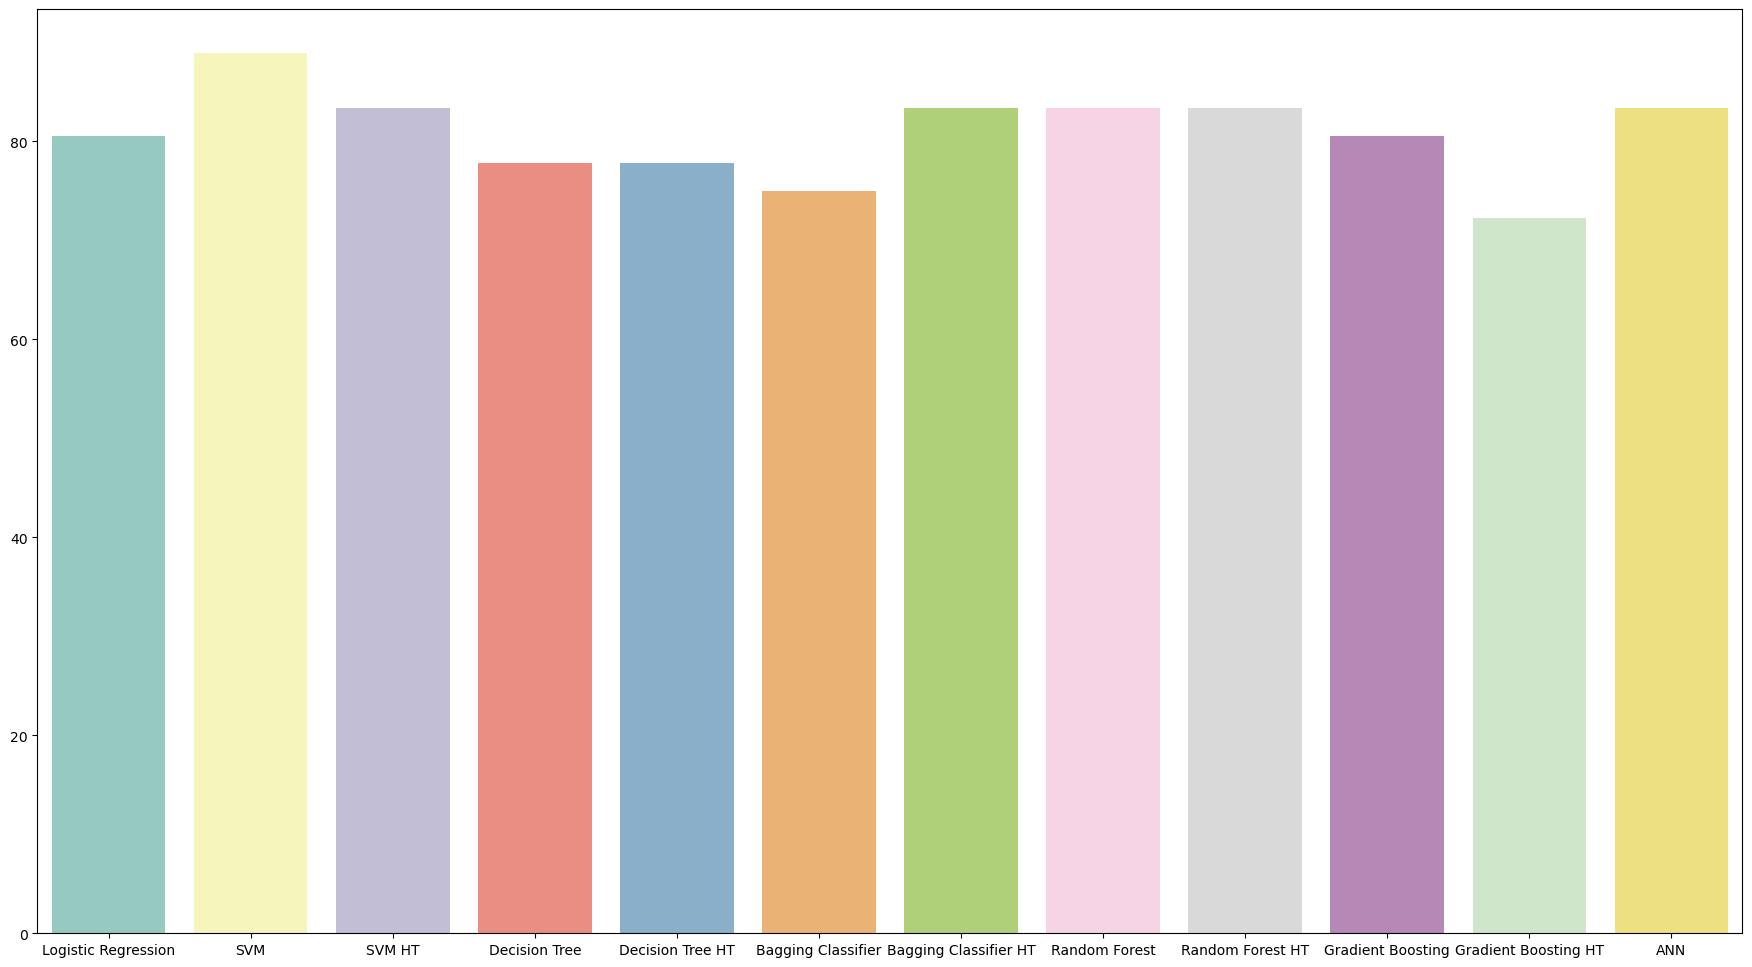

In [193]:
plt.figure(figsize=(22,12))
sns.barplot(x = algorithm,y = accu_score,palette='Set3')
plt.show()

#### Model Accuracy Comparison Report
- A total of 12 models were evaluated using accuracy score.
- SVM achieved the highest accuracy of 88.89%, making it the best-performing model.
- ANN achieved the second-highest accuracy of 86.11%, followed by SVM with Hyperparameter Tuning and Bagging Classifier with Hyperparameter Tuning at 83.33%.
- Decision Tree achieved the lowest accuracy of 75%, while Gradient Boosting with Hyperparameter Tuning achieved 72.22%.

#### Impact of Hyperparameter Tuning (HT):
 - Hyperparameter tuning improved Decision Tree accuracy from 75% to 77.78%.
 - Bagging Classifier accuracy improved from 80.56% to 83.33%.
 - Random Forest accuracy remained unchanged at 83.33%.
 - SVM accuracy decreased from 88.89% to 83.33% after tuning.
 - Gradient Boosting accuracy decreased from 77.78% to 72.22%.

### ALL Algorthim F1 Score

In [169]:
f1_score = [f1_score_lr1,f1_score_svm1,f1_score_svm_ht1,f1_score_dt1,f1_score_dt_ht1,f1_score_bag1,f1_score_bag_ht1,f1_score_rf1,f1_score_rf_ht1,f1_score_gb1,f1_score_gb_ht1,f1_score_ann1]

In [171]:
for i in range(len(algorithm)):
    print("The F1 Score achived usnig "+algorithm[i]+" is: "+str(f1_score[i]))

The F1 Score achived usnig Logistic Regression is: 0.7741935483870968
The F1 Score achived usnig SVM is: 0.8666666666666667
The F1 Score achived usnig SVM HT is: 0.8
The F1 Score achived usnig Decision Tree is: 0.7647058823529411
The F1 Score achived usnig Decision Tree HT is: 0.7142857142857143
The F1 Score achived usnig Bagging Classifier is: 0.7096774193548387
The F1 Score achived usnig Bagging Classifier HT is: 0.8125
The F1 Score achived usnig Random Forest is: 0.8125
The F1 Score achived usnig Random Forest HT is: 0.8125
The F1 Score achived usnig Gradient Boosting is: 0.7878787878787878
The F1 Score achived usnig Gradient Boosting HT is: 0.6428571428571429
The F1 Score achived usnig ANN is: 0.7857142857142857


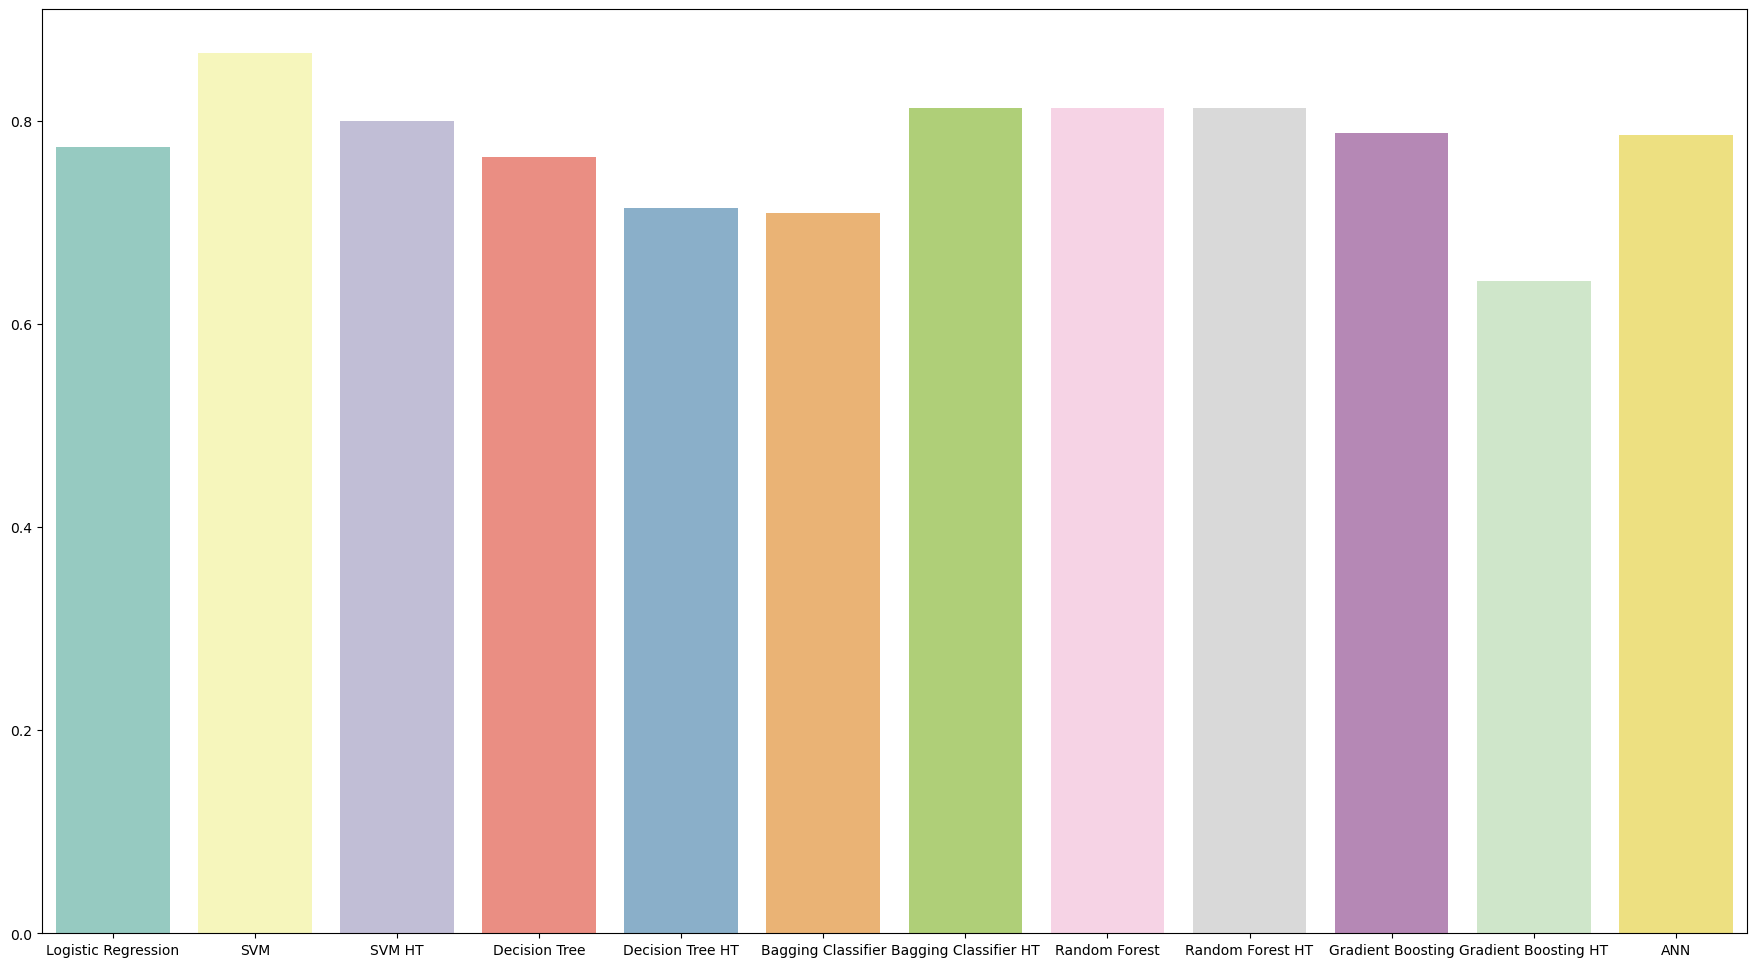

In [190]:
plt.figure(figsize=(22,12))
sns.barplot(x = algorithm,y = f1_score,palette='Set3')
plt.show()

#### F1-Score Comparison Report
- SVM achieved the highest F1-score of 0.867 (86.67%), making it the best-performing model.
- ANN achieved the second-highest F1-score of 0.828 (82.76%).
- Bagging Classifier with Hyperparameter Tuning and Random Forest achieved an F1-score of 0.813 (81.25%).
- Logistic Regression achieved an F1-score of 0.774 (77.42%).
- Decision Tree achieved the lowest F1-score of 0.727 (72.73%) among the models without hyperparameter tuning.
- Gradient Boosting with Hyperparameter Tuning achieved the lowest overall F1-score of 0.643 (64.29%).

#### Impact of Hyperparameter Tuning
- Decision Tree F1-score improved from 72.73% to 76.47%.
- Bagging Classifier improved from 78.79% to 81.25%.
- Random Forest performance remained unchanged at 81.25%.
- SVM F1-score decreased from 86.67% to 80%.
- Gradient Boosting F1-score decreased from 75% to 64.29%.

### ALL Algorithm Recall Score

In [180]:
recall_score = [recall_score_lr1,recall_score_svm1,recall_score_svm_ht1,recall_score_dt1,recall_score_dt_ht1,recall_score_bag1,recall_score_bag_ht1,recall_score_rf1,recall_score_rf_ht1,recall_score_gb1,recall_score_gb_ht1,recall_score_ann1]


In [181]:
for i in range(len(algorithm)):
    print("The Recall Score achived usnig "+algorithm[i]+" is: "+str(recall_score[i]))

The Recall Score achived usnig Logistic Regression is: 0.8
The Recall Score achived usnig SVM is: 0.9285714285714286
The Recall Score achived usnig SVM HT is: 0.8571428571428571
The Recall Score achived usnig Decision Tree is: 0.8125
The Recall Score achived usnig Decision Tree HT is: 0.8333333333333334
The Recall Score achived usnig Bagging Classifier is: 0.7333333333333333
The Recall Score achived usnig Bagging Classifier HT is: 0.8125
The Recall Score achived usnig Random Forest is: 0.8125
The Recall Score achived usnig Random Forest HT is: 0.864406779661017
The Recall Score achived usnig Gradient Boosting is: 0.7647058823529411
The Recall Score achived usnig Gradient Boosting HT is: 0.75
The Recall Score achived usnig ANN is: 0.9166666666666666


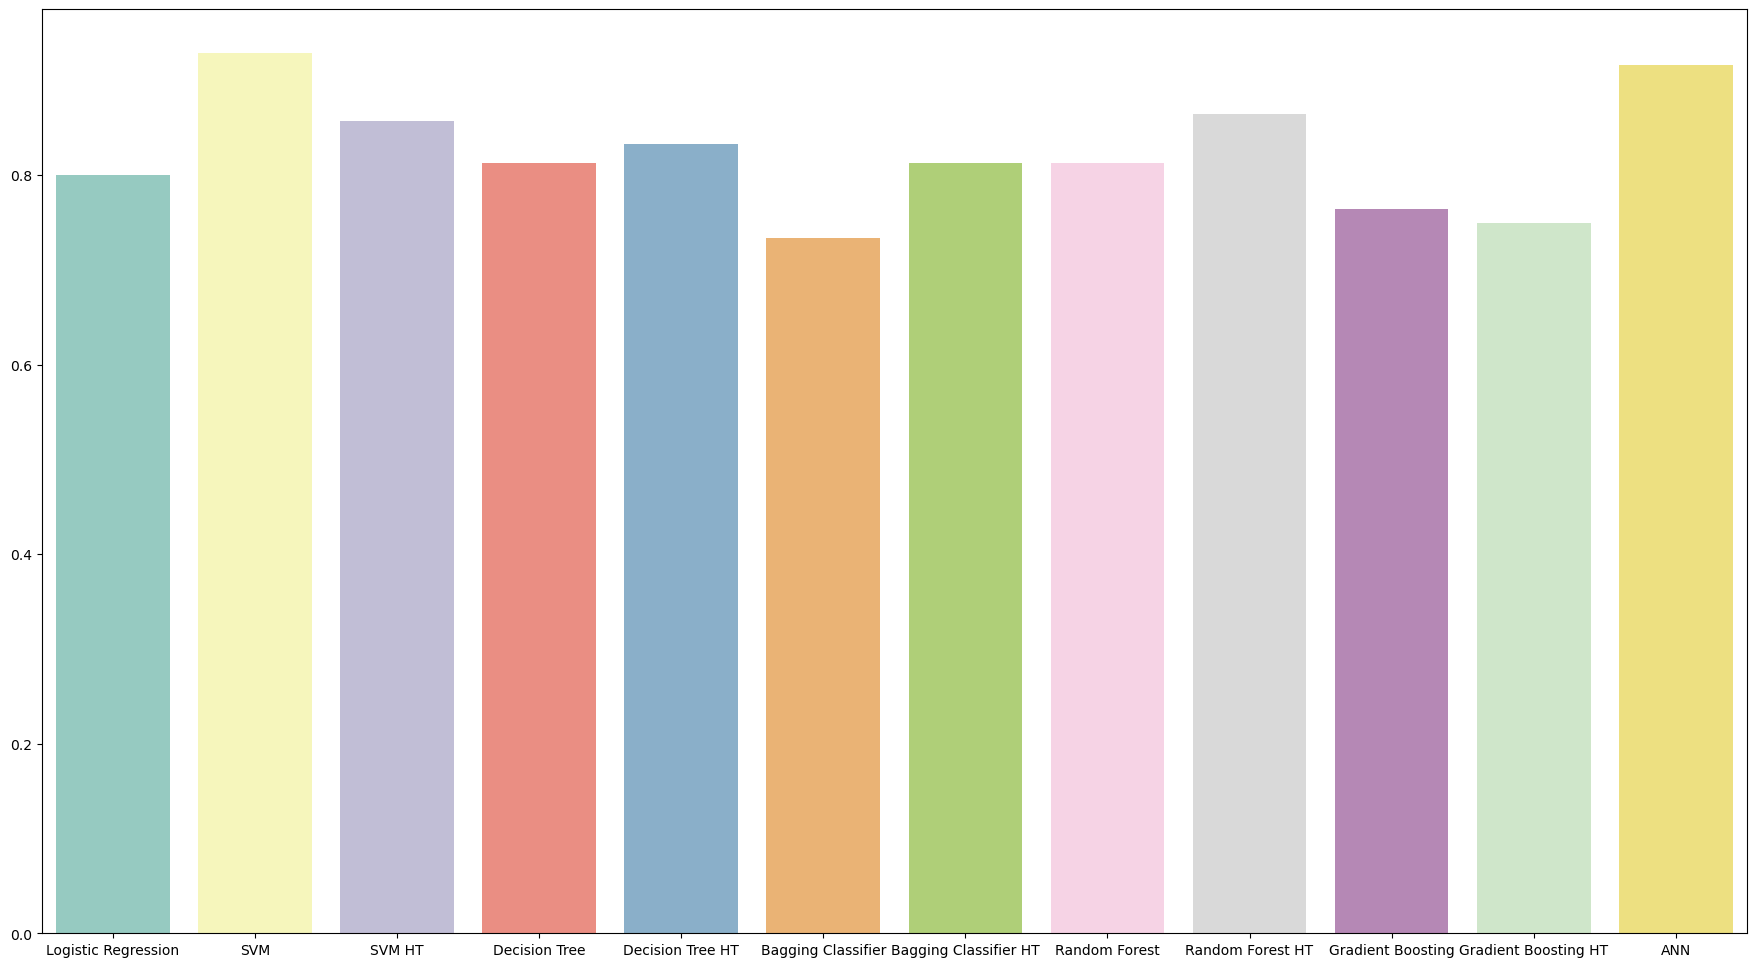

In [191]:
plt.figure(figsize=(22,12))

sns.barplot(x = algorithm,y = recall_score,palette='Set3')
plt.show()

#### Recall Score Comparison Report
- SVM achieved the highest Recall Score of 92.85%, making it the best-performing model.
- ANN achieved the second-highest Recall Score of 92.30%.
- SVM with Hyperparameter Tuning achieved 85% Recall.
- Logistic Regression achieved 80% Recall.
- Gradient Boosting , Gradient Boosting with Hyperparameter Tuning and Decision Tree achived Lowet score is 75%

#### Impact of Hyperparameter Tuning

- Bagging Classifier Recall improved from 76.47% to 81.25%.
- Random Forest Recall imporove from 81.25% to 84%
- SVM Recall decreased from 92.85% to 85.71%.


## Model Selection

After comparing different machine learning algorithms, SVM performed best with 88.89% accuracy, 86.67% F1-score, and 92.86% recall. Therefore, I selected SVM as the best-performing model for this project.

## Task 3: Suggestions to the Hospital

Based on the data analysis and machine learning results, the following suggestions can help hospitals identify heart disease risks at an early stage.

- Hospitals should conduct regular heart health checkups for patients.
- Important health factors like blood pressure, cholesterol, and heart rate should be monitored.
- Machine learning models can help identify patients who may have a risk of heart disease.
- Patients with high-risk predictions should be advised to consult a cardiologist.
- Hospitals should spread awareness about healthy food, regular exercise, and lifestyle habits.
- Regular follow-ups can help monitor patients' health conditions.

**Conclusion:**

These suggestions can help hospitals identify possible heart disease risks early and take proper steps to protect patients. The ML model should be used only as a supporting tool, not as a final medical diagnosis.

## Report on Challenges Faced

During this project, I faced some challenges while analyzing the heart disease dataset and building machine learning models. The following techniques were used to handle these challenges.

### 1. Small Dataset
- **Challenge:** The dataset contained only 180 patient records.
- **Technique Used:** Outlier Capping.
- **Reason:** I used outlier capping instead of removing records because the dataset was small and I wanted to avoid data loss.

### 2. Outliers in Numerical Features
- **Challenge:** Some numerical features contained extreme values.
- **Technique Used:** IQR-based Outlier Capping.
- **Reason:** It helped limit extreme values while keeping all patient records in the dataset.


### 3. Model Overfitting
- **Challenge:** The Decision Tree model achieved 100% training accuracy but only 75% testing accuracy.
- **Technique Used:** Hyperparameter Tuning.
- **Reason:** I adjusted model parameters to control complexity and improve performance on unseen data.

### 4. Model Selection
- **Challenge:** Different machine learning algorithms gave different results.
- **Technique Used:** Model Comparison.
- **Reason:** I compared Accuracy, F1-score, and Recall to select the best-performing model. SVM achieved the highest test accuracy of 88.89%, F1-score of 86.67%, and Recall of 92.86%.

## Conclusion

During this project, I learned how to handle data-related challenges, apply preprocessing techniques, and compare different machine learning algorithms. These steps helped me select SVM as the best-performing model on the given test dataset.